# Phase 3 · 04단원 — 활성화 함수

> 활성화 함수가 없으면 100층 신경망도 **행렬 곱 한 번**입니다.
> 활성화 함수는 신경망이 **곡선으로 생각하게** 해 주는 문입니다.

- 원문: <https://aiengineeringfromscratch.com/lesson?path=phases/03-deep-learning-core/04-activation-functions>
- 예상 시간: 75분
- 먼저 보면 좋은 것: **03단원(역전파)**
- 표시 규칙: 📗 는 원문에 있는 내용, ✨ 는 제가 넣은 예시·실험, ⚠️ 는 원문과 측정이 달랐던 곳입니다.

---

## 03단원이 남긴 숙제를 풉니다

03단원 끝에서 활성화 함수 때문에 생기는 문제를 두 번 만났습니다.

| 03단원의 측정 | 결과 |
| --- | --- |
| 은닉 5층 시그모이드에서 첫 층의 기울기 | 출력층의 **1/19,411** |
| 은닉 뉴런 4개짜리 XOR 신경망을 ReLU 로 바꾸면 | 4개 중 **2개가 죽어서** 손실 0.5 에서 멈춤 |

시그모이드는 깊어지면 기울기가 사라지고, ReLU 는 뉴런이 죽었습니다.
둘 다 **활성화 함수를 뭘 쓰느냐**에서 나온 문제입니다.

> 이 단원은 **어떤 활성화 함수가 어떤 문제를 일으키는지**를 직접 재 보고,
> **뭘 골라야 하는지** 답합니다.

---

## 이 단원이 푸는 문제

📗 원문이 이렇게 시작합니다. 선형 층 둘을 쌓아 봅니다.

$$y = W_2(W_1 x + b_1) + b_2$$

펼치면 이렇게 됩니다.

$$y = (W_2 W_1)\,x + (W_2 b_1 + b_2) = A x + c$$

**층이 둘이었는데 결과는 층 하나**입니다. 층이 100개여도 마찬가지고요.

> 📗 원문: 깊은 선형 신경망은 XOR 을 배울 수 없고, 나선 데이터를 분류할 수 없고, 얼굴을 알아볼 수 없습니다.
> **활성화 함수가 없으면 깊이는 착각입니다.**

그런데 아무 비선형 함수나 넣는다고 끝이 아닙니다.
잘못 고르면 **기울기가 사라지거나**(시그모이드), **뉴런이 영영 죽습니다**(ReLU).
활성화 함수의 선택이 **신경망이 학습을 하느냐 마느냐**를 정합니다.

---

## 이걸 배우면 뭘 할 수 있나

> **"활성화 함수는 뭘 써야 하나요?"**

처음 신경망을 짜면 반드시 마주치는 질문입니다. 이 단원을 지나면 근거를 대고 답할 수 있습니다.

| 질문 | 어디서 | 이 단원의 답 |
| --- | --- | --- |
| 왜 비선형이 꼭 있어야 하나요? | 1절 | 없으면 층을 쌓아도 한 층과 같습니다 |
| 함수마다 뭐가 다른가요? | 2절 | 값의 범위와 기울기의 모양이 다릅니다 |
| 기울기가 사라지는 건 어디서부터인가요? | 3·4절 | 함수마다 구간이 다르고, 측정해 보면 원문 설명과 다른 데도 있습니다 |
| 죽은 뉴런은 얼마나 생기나요? | 5절 | 학습 후에 세어 봅니다 |
| 결국 뭘 쓰나요? | 6·8절 | 용도별 기본값이 있습니다 |

---

## 이 단원의 줄거리

**1절은 왜 비선형이 필요한지**입니다. 선형 층 10개를 곱해서 정말 한 행렬이 되는지 숫자로 확인하고,
선형 모델로 XOR 을 가장 잘 맞추면 어떻게 되는지도 봅니다.

**2절에서 활성화 함수를 하나씩 만듭니다.** 시그모이드, tanh, ReLU, Leaky ReLU, GELU, Swish 여섯 개입니다.
함수마다 **값**과 **기울기**를 같이 짭니다. 기울기가 필요한 이유는 03단원에서 보셨죠. 역전파가 쓰니까요.

**3절은 기울기가 0 에 붙는 구간**을 셉니다. 원문의 `gradient_scan` 이고,
⚠️ 재 보면 **어느 범위에서 세느냐에 따라 순위가 뒤집힙니다.**

**4절이 이 단원의 중심입니다. 소실 기울기**입니다.
📗 원문의 실험을 그대로 돌리면 **ReLU 와 GELU 가 0 으로 사라지고 시그모이드는 멀쩡**합니다. 설명과 반대죠.
왜 그런지 밝히고, 진짜 기울기를 재서 다시 확인합니다.

**5절은 죽은 뉴런**입니다. 📗 원문 탐지기는 학습 전 상태를 봐서 0 개를 찾습니다.
학습이 끝난 뒤에 세면 어떻게 되는지 봅니다.

**6절은 학습 비교**입니다. 원문은 시드 하나로 비교하는데, 시드를 10가지로 바꿔도 순위가 유지되는지 봅니다.

**7절은 소프트맥스**입니다. 은닉층이 아니라 출력층에서 쓰는 함수고, 큰 점수를 넣으면 터지는 문제가 있습니다.

**8절은 📗 연습문제 네 개**입니다. 학습하는 기울기를 가진 PReLU, ELU, 기울기를 감시하는 모니터, 그리고 XOR 에서 다시 하는 비교예요.
2번(50층)은 4절에서 이미 했습니다.

> 한 줄로 줄이면 이렇습니다.
> **비선형이 있어야 깊이가 의미를 갖고, 어떤 비선형이냐가 기울기가 사느냐 죽느냐를 정한다.**

<details>
<summary>절 목록 (펼쳐 보기)</summary>

| 절 | 내용 | 출처 |
| --- | --- | --- |
| 1 | 왜 비선형이어야 하나 | 📗 원문 + ✨ 측정 |
| 2 | 활성화 함수 여섯 가지 만들기 | 📗 원문 + ✨ 그림·검증 |
| 3 | ⚠️ 기울기가 죽는 구간 | 📗 원문 + ✨ 범위 비교 |
| 4 | ⚠️ 소실 기울기 | 📗 원문 + ✨ 반증 |
| 5 | ⚠️ 죽은 뉴런 | 📗 원문 + ✨ 학습 후 측정 |
| 6 | 학습 비교 | 📗 원문 + ✨ 시드 10가지 |
| 7 | 소프트맥스 | 📗 원문 + ✨ 오버플로·온도 |
| 8 | ⚠️ 연습문제 (PReLU · ELU · 감시기 · XOR) | 📗 연습문제 + ✨ 측정 |
| 9 | 정리 · PyTorch · Ship It · 용어 · 퀴즈 | 📗 원문 |

</details>

---

## 먼저 알아 둘 것

<sub>✨ 원문에 없는 보충입니다</sub>

앞 단원을 건너뛰고 오셨어도 읽을 수 있게, 이 단원이 기대는 것만 짚습니다.

| 필요한 것 | 한 줄 설명 | 쓰이는 곳 |
| --- | --- | --- |
| 미분 = 기울기 | 입력을 조금 바꿀 때 출력이 얼마나 바뀌나 | 2절부터 내내. 기울기가 0 이면 그 뉴런은 배우지 못합니다 |
| 지수함수 $e^x$ | $x$ 가 커지면 폭발적으로 커지고, $-x$ 면 0 에 붙습니다 | 시그모이드, tanh, 소프트맥스 |
| 정규분포의 누적확률 $\Phi(x)$ | 표준정규분포에서 $x$ 이하일 확률. $x$ 가 클수록 1 에 가깝습니다 | GELU 만 씁니다 |
| 03단원의 역전파 | 기울기를 출력에서 거꾸로 곱해 나감 | 4절의 소실 기울기 |

### 이름이 낯설다면 — 용어 풀이

<sub>✨ 어원은 영어 사전과 학술 자료에서 널리 알려진 설명을 정리한 것입니다. 한국어 번역어는 분야마다 조금씩 다릅니다.</sub>

| 용어 | 한국어로는 | 영어 어원 | 이 단원에서의 뜻 |
| --- | --- | --- | --- |
| **비선형** nonlinear | 비선형 (非線形) | non-(아닌) + linear. linear 는 라틴어 *linea* '선, 줄'에서 왔습니다 | 직선 하나로 표현되지 않는 것. 곡선을 그릴 수 있다는 뜻 |
| **ReLU** | 렐루 (정류 선형 유닛) | **Re**ctified **L**inear **U**nit. rectify 는 라틴어 *rectus*(곧은) + *facere*(만들다), 곧 '바로잡다'. 전기공학에서 교류의 한쪽 방향만 통과시키는 **정류기**(rectifier)와 같은 모양이라 붙은 이름으로 설명합니다 | 음수는 0 으로 자르고 양수는 그대로 통과시키는 함수 |
| **Tanh** | 쌍곡탄젠트 | hyperbolic tangent. hyperbolic 은 그리스어 *hyperbolē*(hyper 넘어서 + ballein 던지다)에서 온 쌍곡선(hyperbola)의 형용사고, tangent 는 라틴어 *tangere* '닿다'입니다 | −1 과 1 사이로 누르는 S자 곡선 |
| **GELU** | 젤루 (가우스 오차 선형 유닛) | **G**aussian **E**rror **L**inear **U**nit. 가우스(Gauss)는 정규분포의 그 이름이고, error function 은 측정 오차가 정규분포를 따른다는 데서 붙은 이름입니다 | $x$ 에 '$x$ 이하일 정규확률'을 곱한 부드러운 ReLU |
| **SiLU / Swish** | 실루, 스위시 | SiLU 는 **Si**gmoid **L**inear **U**nit 의 줄임입니다. Swish 라는 이름의 뜻은 확실치 않아 생략합니다 | $x$ 에 시그모이드를 곱한 함수 |
| **소프트맥스** softmax | 소프트맥스 | soft + max. 가장 큰 값만 1 로 만드는 max 를 **부드럽게(soft)** 만든 것입니다 | 점수 묶음을 합이 1 인 확률로 바꾸는 함수 |
| **로짓** logit | 로짓 | 보통 logistic unit 의 줄임으로 설명합니다 | 소프트맥스나 시그모이드에 넣기 전의 날것 점수 |
| **포화** saturation | 포화 | 라틴어 *saturare* '가득 채우다'. 더 채울 수 없는 상태입니다 | 입력이 아무리 커져도 출력이 더 안 변하는 평평한 구간 |
| **소실** vanishing | 소실 (消失) | 라틴어 *evanescere* '사라지다'에서 온 vanish. 한자 소실도 사라져 없어진다는 뜻 | 기울기가 층을 거치며 0 에 붙는 현상 |
| **기울기** gradient | 기울기, 경사 | 라틴어 *gradus* '걸음, 계단'. 한 걸음에 얼마나 오르내리는지를 뜻합니다 | 손실을 파라미터로 미분한 것 |

---

## 0. 준비

In [1]:
import math
import random
import time
import warnings

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.font_manager import findfont, FontProperties

warnings.filterwarnings("ignore")

후보들 = ["AppleGothic", "Apple SD Gothic Neo", "Malgun Gothic", "NanumGothic"]
찾은것 = None
for 후보 in 후보들:
    try:
        if 후보.lower().replace(" ", "") in findfont(FontProperties(family=후보)).lower().replace(" ", ""):
            찾은것 = 후보
            break
    except Exception:
        pass
matplotlib.rcParams["font.family"] = ["DejaVu Sans"] + ([찾은것] if 찾은것 else [])
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110

print("준비 끝!  한글 폰트:", 찾은것 or "(없음)")

준비 끝!  한글 폰트: AppleGothic


### 한눈에 보는 지도 — 퍼셉트론 · 시그모이드 · 활성화 함수는 어떻게 이어지나

<sub>✨ 원문에 없는 보충입니다</sub>

01단원에서는 퍼셉트론, 02단원에서는 시그모이드, 이번 단원에서는 활성화 함수. 이름이 줄줄이 나와서 서로 다른 물건처럼 보이기 쉽습니다.
**전부 같은 뉴런 하나의 서로 다른 부분이나 변형**입니다. 그림 한 장으로 먼저 정리합니다.

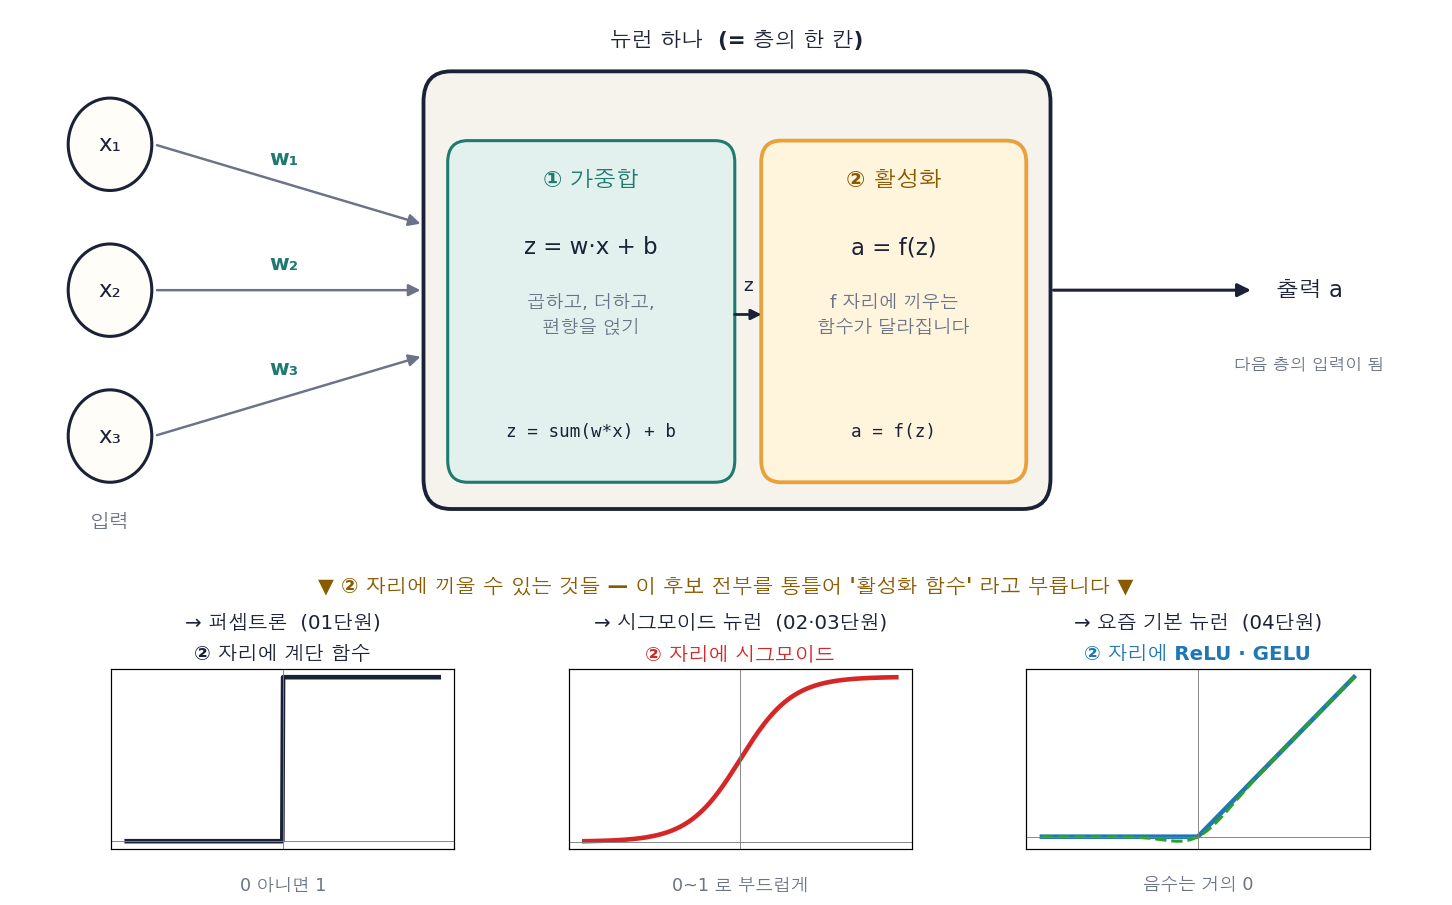

In [2]:
# ✨ 추가 — 뉴런 하나를 한 장으로: ① 가중합 + ② 활성화,  그리고 ② 자리에 뭘 끼우느냐
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch

그림 = plt.figure(figsize=(13, 8.2))
위 = 그림.add_axes([0, 0.38, 1, 0.62])
위.set_xlim(0, 13)
위.set_ylim(0, 4.6)
위.axis("off")

남색, 청록, 호박, 회색 = "#1B2238", "#1F7A70", "#E9A23B", "#6B7388"

# 입력과 가중치
for i, (y, 이름) in enumerate(zip([3.5, 2.3, 1.1], ["x₁", "x₂", "x₃"])):
    위.add_patch(Circle((0.9, y), 0.38, fc="#FFFDF8", ec=남색, lw=2))
    위.text(0.9, y, 이름, ha="center", va="center", fontsize=15, color=남색)
    위.add_patch(FancyArrowPatch((1.3, y), (3.75, 2.3 + (y - 2.3) * 0.45), arrowstyle="-|>", mutation_scale=16, color=회색, lw=1.6))
    위.text(2.35, 2.3 + (y - 2.3) * 0.72 + 0.17, f"w{'₁₂₃'[i]}", fontsize=14, color=청록, fontweight="bold")
위.text(0.9, 0.35, "입력", ha="center", fontsize=13, color=회색)

# 뉴런 몸통
위.add_patch(FancyBboxPatch((3.8, 0.55), 5.6, 3.5, boxstyle="round,pad=0.05,rounding_size=0.25", fc="#F6F3EC", ec=남색, lw=2.5))
위.text(6.6, 4.3, "뉴런 하나  (= 층의 한 칸)", ha="center", fontsize=14, color=남색, fontweight="bold")

위.add_patch(FancyBboxPatch((4.0, 0.75), 2.55, 2.75, boxstyle="round,pad=0.03,rounding_size=0.18", fc="#E3F1EE", ec=청록, lw=2))
위.text(5.275, 3.15, "① 가중합", ha="center", fontsize=15, color=청록, fontweight="bold")
위.text(5.275, 2.6, "z = w·x + b", ha="center", fontsize=15, color=남색)
위.text(5.275, 1.95, "곱하고, 더하고,\n편향을 얹기", ha="center", fontsize=12, color=회색, linespacing=1.5)
위.text(5.275, 1.1, "z = sum(w*x) + b", ha="center", fontsize=11.5, color=남색, family="monospace")

위.add_patch(FancyBboxPatch((6.85, 0.75), 2.35, 2.75, boxstyle="round,pad=0.03,rounding_size=0.18", fc="#FFF4DC", ec=호박, lw=2.5))
위.text(8.025, 3.15, "② 활성화", ha="center", fontsize=15, color="#8A5A00", fontweight="bold")
위.text(8.025, 2.6, "a = f(z)", ha="center", fontsize=15, color=남색)
위.text(8.025, 1.95, "f 자리에 끼우는\n함수가 달라집니다", ha="center", fontsize=12, color=회색, linespacing=1.5)
위.text(8.025, 1.1, "a = f(z)", ha="center", fontsize=11.5, color=남색, family="monospace")

위.add_patch(FancyArrowPatch((6.55, 2.1), (6.85, 2.1), arrowstyle="-|>", mutation_scale=14, color=남색, lw=1.8))
위.text(6.7, 2.3, "z", ha="center", fontsize=12, color=남색)
위.add_patch(FancyArrowPatch((9.45, 2.3), (11.3, 2.3), arrowstyle="-|>", mutation_scale=18, color=남색, lw=2))
위.text(11.8, 2.3, "출력 a", ha="center", va="center", fontsize=15, color=남색)
위.text(11.8, 1.65, "다음 층의 입력이 됨", ha="center", fontsize=11, color=회색)

# 아래: ② 자리에 끼우는 것들
x = np.linspace(-6, 6, 400)
후보들 = [
    ("계단 함수", "퍼셉트론", "01단원", lambda v: (v >= 0) * 1.0, 남색, "0 아니면 1"),
    ("시그모이드", "시그모이드 뉴런", "02·03단원", lambda v: 1 / (1 + np.exp(-v)), "#d62728", "0~1 로 부드럽게"),
    ("ReLU · GELU", "요즘 기본 뉴런", "04단원", lambda v: np.maximum(0, v), "#1f77b4", "음수는 거의 0"),
]
for i, (함수이름, 뉴런이름, 단원, f, 색, 설명) in enumerate(후보들):
    축 = 그림.add_axes([0.07 + i * 0.32, 0.07, 0.24, 0.2])
    축.plot(x, f(x), color=색, lw=3)
    if 함수이름 == "ReLU · GELU":
        축.plot(x, 0.5 * x * (1 + np.tanh(np.sqrt(2 / np.pi) * (x + 0.044715 * x ** 3))), "--", color="#2ca02c", lw=2)
    축.axhline(0, color="gray", lw=0.6)
    축.axvline(0, color="gray", lw=0.6)
    축.set_xticks([])
    축.set_yticks([])
    축.set_title(f"② 자리에 {함수이름}", fontsize=13, color=색, fontweight="bold")
    그림.text(0.07 + i * 0.32 + 0.12, 0.315, f"→ {뉴런이름}  ({단원})", ha="center", fontsize=13, color=남색)
    그림.text(0.07 + i * 0.32 + 0.12, 0.025, 설명, ha="center", fontsize=11.5, color=회색)

그림.text(0.5, 0.355, "▼ ② 자리에 끼울 수 있는 것들 — 이 후보 전부를 통틀어 '활성화 함수' 라고 부릅니다 ▼",
        ha="center", fontsize=13.5, color="#8A5A00", fontweight="bold")
plt.show()

### 그림 읽는 법

뉴런 하나는 **두 칸**으로 나뉩니다.

| 칸 | 하는 일 | 코드로는 | 어느 단원에서 |
| --- | --- | --- | --- |
| **① 가중합** | 입력에 가중치를 곱해 더하고 편향을 얹어 숫자 $z$ 하나를 만듭니다 | `z = sum(w*x) + b` | 01단원의 1절 |
| **② 활성화** | $z$ 를 함수 $f$ 에 넣어 출력 $a$ 를 만듭니다 | `a = f(z)` | 01단원(계단), 02단원(시그모이드), 04단원(전부) |

이 그림으로 세 이름이 풀립니다.

| 이름 | 그림에서 가리키는 것 |
| --- | --- |
| **퍼셉트론** | ① 에 ② 자리에 **계단 함수**를 끼운 뉴런. 01단원의 주인공 |
| **시그모이드** | ② 자리에 끼울 수 있는 **함수 하나**. 계단 대신 이걸 끼우면 02·03단원의 뉴런이 됩니다 |
| **활성화 함수** | ② 자리에 끼울 수 있는 **후보 전부의 총칭**. 시그모이드도, ReLU 도, GELU 도 여기 속합니다 |
| **순전파** | 이 뉴런을 한 층의 모든 칸에 하고 층을 차례로 통과시키는 것. 02단원의 `층` 클래스가 하는 일입니다 |

즉 **퍼셉트론과 시그모이드 뉴런은 ② 칸만 다릅니다.** 이 단원은 그 ② 칸에 뭘 끼워야 하는지를 다룹니다.

---

## 1. 왜 비선형이어야 하나

<sub>📗 원문 "Why Nonlinearity Is Necessary"</sub>

앞에서 본 식으로 돌아갑니다. 선형 층은 $f(x) = Wx + b$ 입니다. 둘을 쌓으면

$$y = W_2(W_1 x + b_1) + b_2 = (W_2 W_1)\,x + (W_2 b_1 + b_2)$$

가 되고, 이건 **행렬 하나와 상수 하나**입니다. 층이 몇 개든 한 층입니다.

📗 원문은 여기에 활성화 함수 $g$ 를 끼우면 식이 안 접힌다고 말합니다.

$$y = W_2\, g(W_1 x + b_1) + b_2$$

$g$ 가 사이에 끼어 있어서 $W_2 W_1$ 로 합칠 수가 없습니다.

말로만 들으면 믿기 어렵습니다. **정말 한 행렬이 되는지** 숫자로 봅니다.

> **실험 1** · 선형 층 10개는 한 행렬이다
>
> **🎯 배울 것** — 선형 층을 몇 개 쌓아도 **합쳐 만든 행렬 하나와 똑같은 결과**가 나옵니다. 그래서 XOR 같은 곡선 문제는 선형 모델로 못 풉니다.
>
> **🔬 하는 일** — 4×4 무작위 행렬 10개를 차례로 곱한 결과와, 10개를 미리 곱해 만든 행렬 하나의 결과를 비교합니다. 그리고 XOR 을 선형 모델로 **가장 잘** 맞추면 출력이 어떻게 되는지 봅니다.

In [3]:
# ✨ 추가 — 선형 층 10개는 정말 한 행렬일까요
rng = np.random.default_rng(0)
층들 = [rng.normal(size=(4, 4)) for _ in range(10)]
x = rng.normal(size=4)

h = x
for W in 층들:
    h = W @ h
한행렬 = np.linalg.multi_dot(층들[::-1])
print("10층을 차례로 통과한 결과 :", np.round(h, 2))
print("합쳐 만든 한 행렬의 결과  :", np.round(한행렬 @ x, 2))
print(f"두 결과의 최대 차이       : {np.abs(h - 한행렬 @ x).max():.1e}")

# XOR 을 선형 모델로 가장 잘 맞춘다면 (최소제곱, 편향 열 포함)
X = np.array([[0, 0, 1], [0, 1, 1], [1, 0, 1], [1, 1, 1.0]])
y = np.array([0, 1, 1, 0.0])
w = np.linalg.lstsq(X, y, rcond=None)[0]
print("\nXOR 에 가장 잘 맞춘 선형 모델의 출력 :", np.round(X @ w, 3))
print("그때의 평균제곱오차                    :", round(float(((X @ w - y) ** 2).mean()), 3))

10층을 차례로 통과한 결과 : [-17.37 179.37  66.18 -92.07]
합쳐 만든 한 행렬의 결과  : [-17.37 179.37  66.18 -92.07]
두 결과의 최대 차이       : 2.8e-14

XOR 에 가장 잘 맞춘 선형 모델의 출력 : [0.5 0.5 0.5 0.5]
그때의 평균제곱오차                    : 0.25


> **👀 주목할 곳** — 앞의 두 줄이 소수 둘째 자리까지 같고 최대 차이는 `2.8e-14` 입니다. 아래쪽은 XOR 에 가장 잘 맞춘 선형 모델의 출력이 네 칸 모두 `0.5` 입니다.
>
> **✅ 알게 된 사실** — 10층의 결과와 한 행렬의 결과가 같습니다. 남은 `2.8e-14` 는 부동소수점 반올림입니다. 그리고 XOR 에서 선형 모델이 할 수 있는 최선은 **전부 0.5 라고 답하는 것**이고, 그때 오차가 0.25 입니다. 층을 100개 쌓아도 더 내려가지 않습니다. 한 행렬이니까요.

> **🧩 이 절의 결론**
>
> 비선형 활성화 함수가 없으면 층을 쌓는 일이 **계산만 늘리고 표현력은 그대로**입니다.
> 02단원에서 XOR 이 풀렸던 건 시그모이드가 층 사이에 끼어 있었기 때문입니다.
>
> **➡️ 다음**
>
> 그렇다면 **어떤 비선형**을 끼울까요? 2절에서 후보 여섯 개를 직접 만들어 봅니다.

---

## 2. 활성화 함수 여섯 가지 만들기

<sub>📗 원문 "Sigmoid" · "Tanh" · "ReLU" · "Leaky ReLU" · "GELU" · "Swish / SiLU" · "Build It Step 1"</sub>

앞 절에서 비선형이면 된다고 했는데, 후보가 꽤 많습니다. 함수마다 **값이 어디로 가는지**와 **기울기가 어떻게 생겼는지**가 다릅니다.
기울기를 같이 보는 이유는 역전파가 그걸 곱해 나가기 때문입니다.

| 함수 | 식 | 값의 범위 | 기울기의 최댓값 |
| --- | --- | --- | --- |
| Sigmoid | $\dfrac{1}{1+e^{-x}}$ | (0, 1) | 0.25 ($x=0$) |
| Tanh | $\dfrac{e^x - e^{-x}}{e^x + e^{-x}}$ | (−1, 1) | 1.0 ($x=0$) |
| ReLU | $\max(0, x)$ | [0, ∞) | 1 ($x>0$) |
| Leaky ReLU | $x$ ($x>0$), $0.01x$ (그 외) | (−∞, ∞) | 1 |
| GELU | $x \cdot \Phi(x)$ | 약 (−0.17, ∞) | 약 1.13 |
| Swish | $x \cdot \text{sigmoid}(x)$ | 약 (−0.28, ∞) | 약 1.10 |

📗 원문의 설명을 한 줄씩 줄이면 이렇습니다.

- **Sigmoid**: 가장 오래된 함수입니다. 기울기가 최대 0.25 라서 층을 거칠수록 줄어듭니다. 출력이 항상 양수라 학습 경로가 지그재그가 된다고도 합니다
- **Tanh**: 시그모이드를 0 중심으로 옮긴 것입니다. 기울기 최대가 1 이라 4배 낫다고 합니다
- **ReLU**: 양수는 그대로, 음수는 0 입니다. 양수 쪽 기울기가 정확히 1 이라 깊은 신경망을 학습 가능하게 만든 함수입니다
- **Leaky ReLU**: 음수 쪽에 작은 기울기(0.01)를 남겨 뉴런이 죽는 걸 막으려는 시도입니다
- **GELU**: BERT·GPT 같은 트랜스포머의 기본값입니다. 부드럽게 ReLU 를 흉내 냅니다
- **Swish**: 구글이 자동 탐색으로 찾았습니다. GELU 와 비슷합니다

표의 "기울기 최댓값"은 3절과 4절에서 숫자로 다시 확인합니다.

> **실험 2** · 함수 여섯 개 만들고 값 찍어 보기
>
> **🎯 배울 것** — 같은 입력에 대해 함수마다 **음수 쪽 값이 어떻게 다른지** 봅니다.
>
> **🔬 하는 일** — 📗 원문의 함수와 미분을 그대로 옮기고, $x$ 를 −2 부터 2 까지 일곱 점에서 값을 찍습니다.

In [4]:
# 📗 원문의 활성화 함수와 미분을 그대로 옮깁니다
def 시그모이드(x):
    x = max(-500, min(500, x))
    return 1.0 / (1.0 + math.exp(-x))


def 시그모이드미분(x):
    s = 시그모이드(x)
    return s * (1 - s)


def 탄에이치(x):
    return math.tanh(x)


def 탄에이치미분(x):
    t = math.tanh(x)
    return 1 - t * t


def 렐루(x):
    return max(0.0, x)


def 렐루미분(x):
    return 1.0 if x > 0 else 0.0


def 리키렐루(x, 알파=0.01):
    return x if x > 0 else 알파 * x


def 리키렐루미분(x, 알파=0.01):
    return 1.0 if x > 0 else 알파


def 젤루(x):
    return 0.5 * x * (1 + math.tanh(math.sqrt(2 / math.pi) * (x + 0.044715 * x ** 3)))


def 젤루미분(x):
    phi = 0.5 * (1 + math.erf(x / math.sqrt(2)))
    pdf = math.exp(-0.5 * x * x) / math.sqrt(2 * math.pi)
    return phi + x * pdf


def 스위시(x):
    return x * 시그모이드(x)


def 스위시미분(x):
    s = 시그모이드(x)
    return s + x * s * (1 - s)


def 소프트맥스(xs):
    최대 = max(xs)
    지수들 = [math.exp(x - 최대) for x in xs]
    합 = sum(지수들)
    return [e / 합 for e in 지수들]


함수들 = {
    "Sigmoid": (시그모이드, 시그모이드미분),
    "Tanh": (탄에이치, 탄에이치미분),
    "ReLU": (렐루, 렐루미분),
    "Leaky ReLU": (리키렐루, 리키렐루미분),
    "GELU": (젤루, 젤루미분),
    "Swish": (스위시, 스위시미분),
}

print(f"{'x':>6}{'sigmoid':>10}{'tanh':>10}{'relu':>10}{'gelu':>10}{'swish':>10}")
print("-" * 56)
for x in [-2.0, -1.0, -0.5, 0.0, 0.5, 1.0, 2.0]:
    print(f"{x:>6.1f}{시그모이드(x):>10.4f}{탄에이치(x):>10.4f}{렐루(x):>10.4f}"
          f"{젤루(x):>10.4f}{스위시(x):>10.4f}")

     x   sigmoid      tanh      relu      gelu     swish
--------------------------------------------------------
  -2.0    0.1192   -0.9640    0.0000   -0.0454   -0.2384
  -1.0    0.2689   -0.7616    0.0000   -0.1588   -0.2689
  -0.5    0.3775   -0.4621    0.0000   -0.1543   -0.1888
   0.0    0.5000    0.0000    0.0000    0.0000    0.0000
   0.5    0.6225    0.4621    0.5000    0.3457    0.3112
   1.0    0.7311    0.7616    1.0000    0.8412    0.7311
   2.0    0.8808    0.9640    2.0000    1.9546    1.7616


> **👀 주목할 곳** — `x = -1.0` 줄. sigmoid 는 `0.2689`, tanh 는 `-0.7616`, relu 는 `0.0000`, gelu 는 `-0.1588`, swish 는 `-0.2689` 입니다.
>
> **✅ 알게 된 사실** — 같은 입력인데 음수 쪽 처리가 다섯 가지로 갈립니다. 0 으로 자르거나(relu), 작은 음수를 남기거나(gelu, swish), 반대편 끝으로 보내거나(tanh), 양수 쪽으로 올립니다(sigmoid). 활성화 함수의 차이는 **음수 입력을 어떻게 다루느냐**에서 대부분 나옵니다.

> **실험 3** · 함수와 미분을 그려 보기
>
> **🎯 배울 것** — 숫자표로는 안 보이는 **기울기의 모양**을 봅니다. 기울기가 0 에 붙는 곳이 학습이 멈추는 곳입니다.
>
> **🔬 하는 일** — −5 에서 5 까지 여섯 함수의 값(왼쪽)과 미분(오른쪽)을 같이 그립니다.

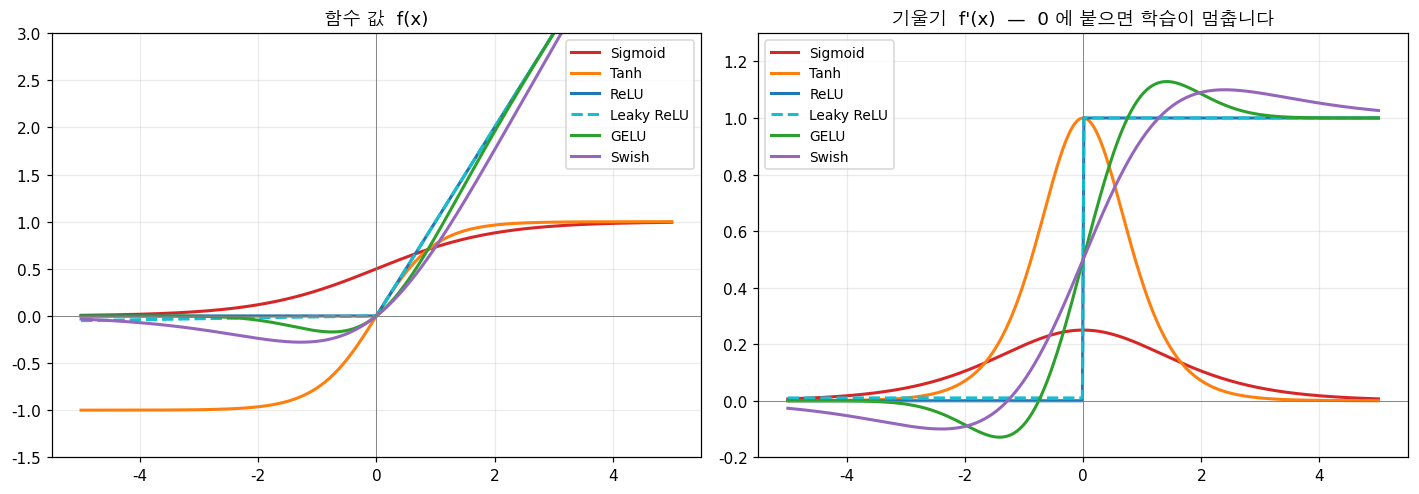

GELU 의 최솟값  -0.1700  (원문: 약 -0.17)
Swish 의 최솟값 -0.2784


In [5]:
# ✨ 추가 — 함수 모양과 미분 모양을 나란히 그립니다
xs = np.linspace(-5, 5, 400)
그림, 축들 = plt.subplots(1, 2, figsize=(13, 4.6))
색들 = ["#d62728", "#ff7f0e", "#1f77b4", "#17becf", "#2ca02c", "#9467bd"]
선들 = ["-", "-", "-", "--", "-", "-"]

for (이름, (f, d)), 색, 선 in zip(함수들.items(), 색들, 선들):
    축들[0].plot(xs, [f(x) for x in xs], 선, color=색, label=이름, lw=2)
    축들[1].plot(xs, [d(x) for x in xs], 선, color=색, label=이름, lw=2)

축들[0].set_ylim(-1.5, 3)
축들[0].set_title("함수 값  f(x)")
축들[1].set_ylim(-0.2, 1.3)
축들[1].set_title("기울기  f'(x)  —  0 에 붙으면 학습이 멈춥니다")
for 축 in 축들:
    축.axhline(0, color="gray", lw=0.6)
    축.axvline(0, color="gray", lw=0.6)
    축.grid(alpha=0.25)
    축.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"GELU 의 최솟값  {min(젤루(x) for x in xs):.4f}  (원문: 약 -0.17)")
print(f"Swish 의 최솟값 {min(스위시(x) for x in xs):.4f}")

> **👀 주목할 곳** — 오른쪽 그림. sigmoid(빨강)는 낮고 넓은 언덕이고, tanh(주황)는 높고 좁은 언덕입니다. ReLU(파랑)는 0 에서 1 로 **계단**을 칩니다.
>
> **✅ 알게 된 사실** — GELU 의 최솟값은 `-0.1700` 으로 📗 원문의 "약 −0.17" 과 맞습니다. Swish 는 `-0.2784` 까지 내려갑니다. 그리고 tanh 의 언덕이 sigmoid 보다 **4배 높지만 훨씬 좁다**는 점이 3절에서 중요해집니다.

> **실험 4** · 옮겨 적은 미분이 맞는지 확인
>
> **🎯 배울 것** — 직접 짠 미분 함수가 맞는지는 **수치미분과 대조해야** 압니다. 03단원에서 한 기울기 검증과 같은 방법입니다.
>
> **🔬 하는 일** — 함수마다 $(f(x+h) - f(x-h)) / 2h$ 와 미분 함수의 값을 −4 에서 4 까지 80개 점에서 비교하고, 가장 큰 차이를 찍습니다.

In [6]:
# ✨ 추가 — 옮겨 적은 미분이 맞는지 수치미분과 대조합니다
h = 1e-5
점들 = [x for x in np.linspace(-4, 4, 81) if abs(x) > 1e-3]   # ReLU 는 0 에서 미분이 정의되지 않아 피합니다

print(f"{'함수':<12}{'미분 함수 vs 수치미분, 최대 차이':>34}")
print("-" * 46)
for 이름, (f, d) in 함수들.items():
    차이 = max(abs((f(x + h) - f(x - h)) / (2 * h) - d(x)) for x in 점들)
    print(f"{이름:<12}{차이:>34.2e}")

함수                        미분 함수 vs 수치미분, 최대 차이
----------------------------------------------
Sigmoid                               9.27e-12
Tanh                                  3.29e-11
ReLU                                  1.57e-11
Leaky ReLU                            1.57e-11
GELU                                  8.67e-04
Swish                                 4.90e-11


> **👀 주목할 곳** — 맨 아래 가까이 `GELU` 줄의 `8.67e-04`. 나머지 다섯 줄은 `1e-11` 근처입니다.
>
> **✅ 알게 된 사실** — ⚠️ 📗 원문의 `gelu_derivative` 는 **정확한 $\Phi(x)$** 로 미분을 계산하는데, `gelu` 는 **tanh 근사**로 값을 계산합니다. 두 함수가 사실 서로 다른 함수의 짝이라서 차이가 `8.7e-4` 만큼 남습니다. 실제 학습에 영향을 줄 크기는 아니지만, **근사한 순전파에는 근사의 미분이 맞습니다.** PyTorch 의 `gelu(approximate='tanh')` 같은 옵션이 따로 있는 이유이기도 합니다.

> **🧩 이 절의 결론**
>
> 여섯 함수 모두 만들었고, 미분도 수치미분과 맞습니다(GELU 는 근사 차이 8.7e-4).
> 차이는 **음수 입력을 어떻게 처리하느냐**와 **기울기 언덕의 폭**입니다.
>
> **➡️ 다음**
>
> 그 언덕 바깥에서는 기울기가 0 에 붙습니다. 3절에서 **그 구간이 얼마나 넓은지** 셉니다.

---

## 3. 기울기가 죽는 구간

<sub>📗 원문 "Build It Step 2"</sub>

기울기가 0 에 가까우면 가중치가 안 바뀝니다. 그러니 **기울기가 0 에 붙는 구간이 넓을수록 위험**합니다.

📗 원문의 `gradient_scan` 은 −5 에서 5 까지를 100칸으로 나누고, 기울기가 0.01 보다 작은 칸의 비율을 셉니다.
결과는 **Sigmoid 9%, Tanh 41%, ReLU 51%, Leaky ReLU 0%, GELU 20%, Swish 1%** 입니다.

이 숫자를 보면 이상한 점이 있습니다. tanh 는 시그모이드보다 4배 낫다고 했는데 **죽은 구간은 4배 넓습니다.**
그리고 −5 에서 5 라는 범위는 누가 정한 걸까요. 범위를 바꿔 보면 숫자가 어떻게 되는지 확인합니다.

> **실험 5** · 범위를 바꾸면 순위가 바뀌나
>
> **🎯 배울 것** — "죽은 구간 비율"은 **어느 범위에서 세느냐에 따라 달라지는** 숫자입니다.
>
> **🔬 하는 일** — 같은 `gradient_scan` 을 ±5, ±10, ±20 에서 돌립니다. 그리고 sigmoid 와 tanh 의 기울기가 처음 0.01 아래로 떨어지는 지점을 찾습니다.

In [7]:
# 📗 원문의 gradient_scan 을 범위를 바꿔 가며 돌립니다 (한 칸 0.1)
def 죽은구간비율(미분, 범위):
    칸수 = int(2 * 범위 / 0.1)
    return sum(abs(미분(-범위 + i * 0.1)) < 0.01 for i in range(칸수)) / 칸수 * 100


print("기울기가 0.01 보다 작은 구간의 비율 (%)\n")
print(f"{'범위':<12}" + "".join(f"{이름:>12}" for 이름 in 함수들))
print("-" * 84)
for 범위 in (5, 10, 20):
    print(f"{'±' + str(범위):<12}" + "".join(f"{죽은구간비율(d, 범위):>11.0f}%" for _, (f, d) in 함수들.items()))

# ✨ 어디서부터 둔해지나 (x > 0 쪽에서 처음 0.01 아래로 내려가는 지점)
print("\n기울기가 처음 0.01 아래로 내려가는 |x|")
for 이름, 미분 in [("Sigmoid", 시그모이드미분), ("Tanh", 탄에이치미분)]:
    경계 = next(i * 0.001 for i in range(0, 12000) if 미분(i * 0.001) < 0.01)
    print(f"  {이름:<8} |x| > {경계:.3f}")

기울기가 0.01 보다 작은 구간의 비율 (%)

범위               Sigmoid        Tanh        ReLU  Leaky ReLU        GELU       Swish
------------------------------------------------------------------------------------
±5                    9%         41%         51%          0%         20%          1%
±10                  55%         70%         50%          0%         35%         20%
±20                  77%         85%         50%          0%         42%         35%

기울기가 처음 0.01 아래로 내려가는 |x|
  Sigmoid  |x| > 4.585
  Tanh     |x| > 2.994


> **👀 주목할 곳** — `±5` 줄은 원문과 같고(9, 41, 51, 0, 20, 1), `Sigmoid` 열이 `9% → 55% → 77%` 로 올라갑니다. `ReLU` 열은 `51, 50, 50` 에서 움직이지 않습니다.
>
> **✅ 알게 된 사실** — ⚠️ **범위가 넓어지면 sigmoid 가 ReLU 를 추월합니다.** ±10 에서 sigmoid 55%, ReLU 50% 입니다. ReLU 는 반직선이라 범위와 무관하게 절반이고, 포화하는 함수들은 범위가 넓을수록 비율이 올라갑니다. tanh 는 어느 범위에서나 sigmoid 보다 넓습니다. 이유는 아래쪽 두 줄에 있습니다. tanh 는 `|x| > 2.994` 부터, sigmoid 는 `|x| > 4.585` 부터 둔해집니다. **언덕이 높은 대신 좁아서**입니다.

> **🧩 이 절의 결론**
>
> "죽은 구간 비율"은 비교 기준이 아닙니다. 재는 범위에 따라 순위가 바뀝니다.
> 믿을 만한 정보는 **어디서부터 둔해지나**입니다. sigmoid 는 약 4.6, tanh 는 약 3.0 입니다.
> 입력이 이 값을 넘는 순간 그 뉴런은 거의 배우지 못합니다.
>
> **➡️ 다음**
>
> 이 구간을 층마다 한 번씩 거치면 기울기가 곱해져 줄어듭니다. 4절이 그 **소실 기울기**입니다.

---

## 4. 소실 기울기

<sub>📗 원문 "Sigmoid" · "Gradient Flow Comparison" · "Build It Step 3"</sub>

📗 원문의 주장은 이렇습니다.

> 시그모이드 기울기의 최댓값은 0.25 입니다. 10층이면 $0.25^{10} = 0.000000953674$,
> 원래 신호의 100만분의 1 도 안 됩니다. 앞쪽 층은 사실상 얼어붙습니다.

그리고 그림에서 **첫 층 기울기**를 이렇게 적습니다. Sigmoid 약 0.000001, Tanh 약 0.001, ReLU 약 1.0, GELU 약 0.8.

이걸 보이는 실험이 `vanishing_gradient_experiment` 입니다. 먼저 그대로 돌려 봅니다.

> **실험 6** · 📗 원문의 소실 기울기 실험
>
> **🎯 배울 것** — 원문 실험이 **정말 기울기를 재는지** 확인합니다.
>
> **🔬 하는 일** — 코드를 그대로 옮겨 sigmoid, ReLU, GELU 를 10층 통과시키고 층마다 출력의 크기를 찍습니다.

In [8]:
# 📗 원문의 '소실 기울기 실험' 을 그대로 옮깁니다 (순수 파이썬)
def 원문실험(활성, 층수=10, 입력수=5):
    random.seed(42)
    값들 = [random.gauss(0, 1) for _ in range(입력수)]
    크기들 = []
    for _ in range(층수):
        가중치 = [random.gauss(0, 1) for _ in range(입력수)]
        z = sum(w * v for w, v in zip(가중치, 값들))
        출력 = 활성(z)
        크기들.append(abs(출력))
        값들 = [출력] * 입력수      # 📗 이번 층의 출력 하나를 다음 층의 입력 5개로 복사합니다
    return 크기들


결과들 = {이름: 원문실험(f) for 이름, f in [("Sigmoid", 시그모이드), ("ReLU", 렐루), ("GELU", 젤루)]}
print("층별 출력 크기 |activation|  — 📗 원문이 '기울기가 사라지는 걸 보인다' 고 한 실험\n")
print(f"{'층':>3}" + "".join(f"{이름:>12}" for 이름 in 결과들))
print("-" * 39)
for i in range(10):
    print(f"{i + 1:>3}" + "".join(f"{결과들[이름][i]:>12.6f}" for 이름 in 결과들))

print("\nReLU 의 6~10층 출력이 전부 정확히 0.0 인가:", all(v == 0.0 for v in 결과들["ReLU"][5:]))

층별 출력 크기 |activation|  — 📗 원문이 '기울기가 사라지는 걸 보인다' 고 한 실험

  층     Sigmoid        ReLU        GELU
---------------------------------------
  1    0.505242    0.020967    0.010659
  2    0.672564    0.029871    0.007685
  3    0.579702    0.014281    0.001842
  4    0.518791    0.001853    0.000120
  5    0.506911    0.000099    0.000003
  6    0.070461    0.000000    0.000008
  7    0.502930    0.000000    0.000001
  8    0.645463    0.000000    0.000000
  9    0.521604    0.000000    0.000000
 10    0.662811    0.000000    0.000000

ReLU 의 6~10층 출력이 전부 정확히 0.0 인가: True


> **👀 주목할 곳** — Sigmoid 열은 `0.5` 언저리에 머물고(6층만 `0.07`), ReLU 열은 6층부터 `0.000000` 이며, GELU 열도 `0.000001` 아래로 내려갑니다. 맨 아래 줄은 `True` 입니다.
>
> **✅ 알게 된 사실** — ⚠️ **설명과 정반대입니다.** 사라지는 쪽은 ReLU 와 GELU 고 시그모이드는 멀쩡합니다. 이유는 이 실험이 **순전파 출력의 크기**를 재기 때문입니다. 기울기가 아닙니다. 게다가 이전 층 출력 하나를 다음 층 입력 5개에 복사하니, 어느 층에서 출력이 정확히 0 이 되면 다음 층의 $z$ 가 전부 0 이고, `relu(0) = 0` 이라 **끝까지 0** 입니다. 시그모이드는 `sigmoid(0) = 0.5` 라서 0 에 갇히지 않습니다. 그러니 이 실험은 소실 기울기를 보여 주지 못하고, 다른 현상을 보여 줍니다.

그러면 진짜 기울기를 재 봅니다. 03단원에서 만든 것과 같은 일입니다.
순전파로 값을 쌓아 두고, 출력에서 거꾸로 기울기를 흘려, **층마다 가중치 기울기의 크기**를 적습니다.

> **실험 7** · 층마다 기울기가 얼마나 남나
>
> **🎯 배울 것** — 소실 기울기는 **활성화 함수와 초기화가 함께** 만드는 현상입니다. 시그모이드만의 문제가 아닙니다.
>
> **🔬 하는 일** — 층 너비 32, 10층 신경망에서 활성화 함수 네 개로 역전파해 1층과 10층의 기울기 크기를 비교합니다. 가중치 크기를 두 가지(분산 $1/n$, $2/n$)로 바꿔서 봅니다.


[가중치 분산 1/너비 (Xavier 식)]  10층, 층 너비 32

활성화              첫 층 기울기         마지막 층 기울기       마지막 / 첫         마지막 층 출력 크기
----------------------------------------------------------------------------
Sigmoid         1.41e-06          3.86e+00     2748282.8              0.5168
Tanh            8.79e-01          7.25e-01           0.8              0.1469
ReLU            4.22e-01          9.96e-01           2.4              0.0207
GELU            9.17e-03          2.77e-02           3.0              0.0013

[가중치 분산 2/너비 (He 식, ReLU 용)]  10층, 층 너비 32

활성화              첫 층 기울기         마지막 층 기울기       마지막 / 첫         마지막 층 출력 크기
----------------------------------------------------------------------------
Sigmoid         1.62e-05          3.76e+00      232599.7              0.5217
Tanh            2.35e+00          1.25e+00           0.5              0.4299
ReLU            9.54e+00          2.25e+01           2.4              0.6633
GELU            9.69e+00          1.03e+01           1.1           

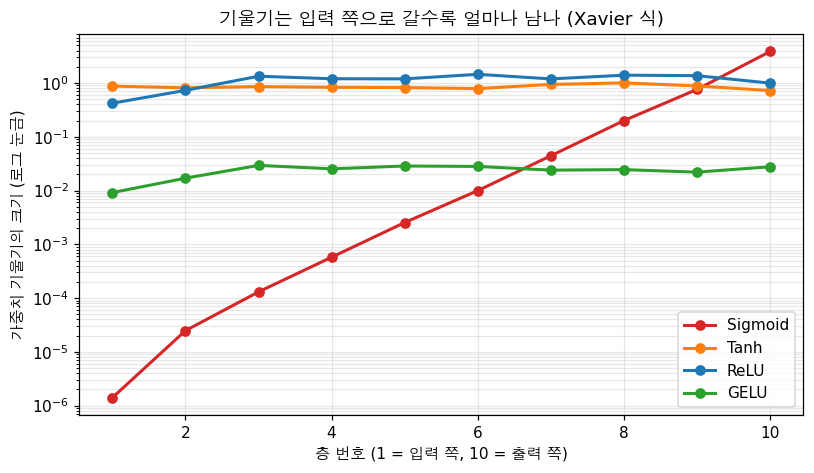

In [9]:
# ✨ 추가 — 진짜 기울기를 잽니다: 출력에서 거꾸로 흘려 층마다 가중치 기울기의 크기를 봅니다
넘파이 = {이름: (np.vectorize(f), np.vectorize(d)) for 이름, (f, d) in 함수들.items()}


def 층별기울기(이름, 깊이=10, 너비=32, 배치=64, 시드=0, 배율=1.0):
    활성, 미분 = 넘파이[이름]
    rng = np.random.default_rng(시드)
    X = rng.normal(size=(배치, 너비))
    Ws = [rng.normal(size=(너비, 너비)) * np.sqrt(배율 / 너비) for _ in range(깊이)]

    h, zs, hs = X, [], [X]
    for W in Ws:                       # 순전파
        z = h @ W
        zs.append(z)
        h = 활성(z)
        hs.append(h)

    g = np.ones_like(h) / 배치         # 출력에서 시작하는 기울기
    크기들 = []
    for l in reversed(range(깊이)):    # 역전파
        gz = g * 미분(zs[l])
        크기들.append(np.linalg.norm(hs[l].T @ gz))
        g = gz @ Ws[l].T
    return 크기들[::-1], float(np.abs(h).mean())


대상 = ["Sigmoid", "Tanh", "ReLU", "GELU"]
for 배율, 설명 in [(1.0, "가중치 분산 1/너비 (Xavier 식)"), (2.0, "가중치 분산 2/너비 (He 식, ReLU 용)")]:
    print(f"\n[{설명}]  10층, 층 너비 32\n")
    print(f"{'활성화':<10}{'첫 층 기울기':>14}{'마지막 층 기울기':>18}{'마지막 / 첫':>14}{'마지막 층 출력 크기':>20}")
    print("-" * 76)
    for 이름 in 대상:
        크기들, 출력크기 = 층별기울기(이름, 배율=배율)
        print(f"{이름:<10}{크기들[0]:>14.2e}{크기들[-1]:>18.2e}{크기들[-1] / 크기들[0]:>14.1f}{출력크기:>20.4f}")

print(f"\n📗 원문의 0.25^10 = {0.25 ** 10:.3e}   →  1 / 0.25^10 = {1 / 0.25 ** 10:,.0f} 배")

그림, 축 = plt.subplots(figsize=(7.5, 4.4))
for 이름, 색 in zip(대상, ["#d62728", "#ff7f0e", "#1f77b4", "#2ca02c"]):
    크기들, _ = 층별기울기(이름, 배율=1.0)
    축.semilogy(range(1, 11), 크기들, "o-", color=색, label=이름, lw=2)
축.set_xlabel("층 번호 (1 = 입력 쪽, 10 = 출력 쪽)")
축.set_ylabel("가중치 기울기의 크기 (로그 눈금)")
축.set_title("기울기는 입력 쪽으로 갈수록 얼마나 남나 (Xavier 식)")
축.grid(alpha=0.3, which="both")
축.legend()
plt.tight_layout()
plt.show()

> **👀 주목할 곳** — 표의 `마지막 / 첫` 열. Xavier 식에서 Sigmoid 는 `2748282.8`, Tanh 는 `0.8`, ReLU 는 `2.4`, GELU 는 `3.0` 입니다. He 식에서는 `232599.7`, `0.5`, `2.4`, `1.1` 입니다. 그림에서는 sigmoid 선만 아래로 곤두박질칩니다.
>
> **✅ 알게 된 사실** — 📗 원문의 **sigmoid 는 맞습니다.** 출력층 대비 첫 층 기울기가 Xavier 식에서 약 275만 배 작습니다. $1/0.25^{10} = 1{,}048{,}576$ 의 2.6배로, 가중치까지 곱해지기 때문에 원문 숫자보다 조금 더 나쁩니다. 그런데 ⚠️ **tanh 는 거의 안 사라집니다.** 원문이 말한 "약 0.001" 은 안 나오고, 첫 층과 마지막 층이 비슷합니다(0.8배, 0.5배). 입력이 작을 때 tanh 의 기울기가 1 에 가깝기 때문입니다. 또 ⚠️ **GELU 의 기울기 크기는 가중치 크기에 따라 크게 달라집니다.** Xavier 식에서는 마지막 층의 출력 크기가 `0.0013` 으로 쪼그라들어 첫 층 기울기가 `9.17e-03` 인데, He 식에서는 `9.69` 입니다. ReLU 용으로 알려진 He 초기화가 GELU 에도 맞는다는 걸 숫자가 보여 줍니다.

> **실험 8** · 📗 연습문제 2번 — 50층으로
>
> **🎯 배울 것** — 층이 50개면 **어느 조합이 살아남는지** 봅니다.
>
> **🔬 하는 일** — 같은 실험을 깊이 50 으로 돌려 첫 층의 기울기 크기를 찍습니다.

In [10]:
# 📗 연습문제 2번 — 50층으로 늘려 봅니다 (첫 층의 기울기 크기)
print(f"{'활성화':<10}{'Xavier 식, 첫 층':>20}{'He 식, 첫 층':>18}")
print("-" * 48)
for 이름 in 대상:
    a = 층별기울기(이름, 깊이=50, 배율=1.0)[0][0]
    b = 층별기울기(이름, 깊이=50, 배율=2.0)[0][0]
    print(f"{이름:<10}{a:>20.2e}{b:>18.2e}")

활성화              Xavier 식, 첫 층         He 식, 첫 층
------------------------------------------------
Sigmoid               1.63e-31          3.44e-25
Tanh                  2.99e-01          1.64e+01


ReLU                  9.98e-08          2.37e+00
GELU                  1.12e-14          4.05e-04


> **👀 주목할 곳** — `Sigmoid` 줄의 `1.63e-31` 과 `3.44e-25`. 그리고 `Tanh` 줄의 `2.99e-01` 과 `1.64e+01`.
>
> **✅ 알게 된 사실** — 50층에서 시그모이드는 어떤 초기화로도 죽습니다(1e-31, 1e-25). tanh 는 두 경우 모두 살아 있습니다. ReLU 는 Xavier 식이면 `9.98e-08` 로 거의 죽고 He 식이면 `2.37` 로 삽니다. GELU 는 He 식에서도 `4.05e-04` 라 ReLU 만큼 안정적이지 않습니다. 정리하면 **소실 기울기는 "시그모이드 때문"이 아니라 "활성화 함수의 평균 기울기 × 가중치 크기"가 1 보다 작으냐 크냐**의 문제입니다. 시그모이드는 이 곱이 어떤 초기화로도 1 보다 훨씬 작게 나옵니다.

> **🧩 이 절의 결론**
>
> 📗 원문의 실험(6)은 순전파를 재서 설명과 반대로 나왔습니다. 진짜 기울기(7, 8)로 재면
> **시그모이드만 확실히 죽고, tanh 는 의외로 버팁니다.** ReLU·GELU 는 초기화를 맞춰야 삽니다.
>
> **➡️ 다음**
>
> 그렇다면 ReLU 는 안전할까요? 03단원에서 ReLU 뉴런이 죽는 걸 이미 봤습니다. 5절에서 **얼마나 죽는지** 셉니다.

---

## 5. 죽은 뉴런

<sub>📗 원문 "ReLU: The Breakthrough" · "Build It Step 4"</sub>

ReLU 에는 약점이 있습니다. 어떤 뉴런의 입력이 **항상 음수**면 출력도 기울기도 항상 0 이라 **영영 되살아나지 못합니다.**
📗 원문은 "실제로 ReLU 신경망에서 뉴런의 10~40% 가 학습 중에 죽을 수 있다" 고 합니다.

원문의 탐지기는 뉴런 20개에 입력 1000개를 넣고 한 번도 안 켜진 뉴런을 셉니다. 돌려 봅니다.

> **실험 9** · 📗 원문의 죽은 뉴런 탐지기
>
> **🎯 배울 것** — 원문 탐지기가 **어떤 상태의 신경망**을 보는지 확인합니다.
>
> **🔬 하는 일** — 코드를 옮겨 뉴런 20개, 입력 1000개로 돌려 뉴런마다 켜진 횟수를 셉니다.

In [11]:
# 📗 원문의 죽은 뉴런 탐지기를 옮깁니다 — 학습 전, 무작위 가중치 상태를 봅니다
def 죽은뉴런탐지(입력수=5, 은닉수=20, 표본수=1000):
    random.seed(0)
    가중치 = [[random.gauss(0, 1) for _ in range(입력수)] for _ in range(은닉수)]
    편향들 = [random.gauss(0, 1) for _ in range(은닉수)]
    발화 = [0] * 은닉수
    for _ in range(표본수):
        입력 = [random.gauss(0, 1) for _ in range(입력수)]
        for i in range(은닉수):
            z = sum(w * x for w, x in zip(가중치[i], 입력)) + 편향들[i]
            if 렐루(z) > 0:
                발화[i] += 1
    return 발화


발화 = 죽은뉴런탐지()
죽음 = sum(1 for c in 발화 if c == 0)
약함 = sum(1 for c in 발화 if 0 < c < 50)
print(f"뉴런 20개, 입력 1000개  →  죽은 뉴런 {죽음}개, 거의 안 켜지는 뉴런 {약함}개")
print(f"뉴런별 발화 횟수: 최소 {min(발화)}, 최대 {max(발화)}")

뉴런 20개, 입력 1000개  →  죽은 뉴런 0개, 거의 안 켜지는 뉴런 0개
뉴런별 발화 횟수: 최소 187, 최대 750


> **👀 주목할 곳** — `죽은 뉴런 0개`, 그리고 발화 횟수의 최솟값 `187`.
>
> **✅ 알게 된 사실** — ⚠️ 탐지기는 **학습 전 무작위 가중치**를 봅니다. 그 상태에서는 죽은 뉴런이 하나도 없습니다. 가장 덜 켜지는 뉴런도 1000번 중 187번 켜집니다. 죽은 뉴런은 **학습하는 동안** 생기는 것이라, 이 탐지기로는 📗 원문의 "10~40%" 를 확인할 수 없습니다.

그러면 학습이 끝난 뒤에 세 봅니다. 6절에서 쓸 신경망(은닉 8개)을 먼저 정의하고, 그 신경망을 학습률 세 가지로 학습시킨 뒤
**200개 입력 전부에서 꺼져 있는 뉴런**을 셉니다. GELU 는 0 이 되는 일이 없으니 **기울기가 0.01 아래로 떨어진 뉴런**으로 셉니다.

In [12]:
# 📗 원문의 ActivationNetwork 를 옮깁니다. 시드만 바꿀 수 있게 인자로 뺐습니다
def 원데이터만들기(n=200, 시드=42):
    random.seed(시드)
    데이터 = []
    for _ in range(n):
        x = random.uniform(-2, 2)
        y = random.uniform(-2, 2)
        데이터.append(([x, y], 1.0 if x * x + y * y < 1.5 else 0.0))
    return 데이터


class 활성망:
    def __init__(self, 활성, 미분, 은닉수=8, 학습률=0.1, 시드=0):
        random.seed(시드)
        self.act, self.act_d, self.lr, self.n = 활성, 미분, 학습률, 은닉수
        self.w1 = [[random.gauss(0, 0.5) for _ in range(2)] for _ in range(은닉수)]
        self.b1 = [0.0] * 은닉수
        self.w2 = [random.gauss(0, 0.5) for _ in range(은닉수)]
        self.b2 = 0.0

    def 순전파(self, x):
        self.x = x
        self.z1 = [self.w1[i][0] * x[0] + self.w1[i][1] * x[1] + self.b1[i] for i in range(self.n)]
        self.h = [self.act(z) for z in self.z1]
        self.z2 = sum(self.w2[i] * self.h[i] for i in range(self.n)) + self.b2
        self.out = 시그모이드(self.z2)
        return self.out

    def 역전파(self, 정답):
        d_out = (self.out - 정답) * self.out * (1 - self.out)
        for i in range(self.n):
            d_h = d_out * self.w2[i] * self.act_d(self.z1[i])
            self.w2[i] -= self.lr * d_out * self.h[i]
            for j in range(2):
                self.w1[i][j] -= self.lr * d_h * self.x[j]
            self.b1[i] -= self.lr * d_h
        self.b2 -= self.lr * d_out

    def 학습(self, 데이터, 에포크=200):
        손실들 = []
        for _ in range(에포크):
            총 = 0.0
            for x, y in 데이터:
                예측 = self.순전파(x)
                self.역전파(y)
                총 += (예측 - y) ** 2
            손실들.append(총 / len(데이터))
        return 손실들

    def 정확도(self, 데이터):
        return sum((self.순전파(x) >= 0.5) == (y >= 0.5) for x, y in 데이터) / len(데이터) * 100


데이터 = 원데이터만들기()
print("📗 원문의 '학습 비교' (시드 0, 은닉 8, 학습률 0.1, 200 에포크)\n")
print(f"{'활성화':<10}{'처음 손실':>12}{'끝 손실':>12}{'줄어든 비율':>14}{'끝 정확도':>12}")
print("-" * 60)
for 이름 in ["Sigmoid", "ReLU", "GELU"]:
    f, d = 함수들[이름]
    망 = 활성망(f, d)
    손실들 = 망.학습(데이터)
    print(f"{이름:<10}{손실들[0]:>12.4f}{손실들[-1]:>12.4f}{(1 - 손실들[-1] / 손실들[0]) * 100:>13.1f}%{망.정확도(데이터):>11.1f}%")

📗 원문의 '학습 비교' (시드 0, 은닉 8, 학습률 0.1, 200 에포크)

활성화              처음 손실        끝 손실        줄어든 비율       끝 정확도
------------------------------------------------------------


Sigmoid         0.2222      0.0319         85.6%       97.5%


ReLU            0.2232      0.0102         95.4%       99.5%


GELU            0.2225      0.0056         97.5%       99.5%


> **🧩 학습 비교는 6절에서 이어집니다.** 위 표는 📗 원문의 '시드 0 하나' 결과를 그대로 재현한 것입니다. 여기서는 신경망 클래스를 먼저 만들었다는 점만 기억해 주세요.

> **실험 10** · 학습이 끝난 뒤 죽은 뉴런
>
> **🎯 배울 것** — ReLU 뉴런이 **학습 중에 실제로 얼마나 죽는지**, GELU 는 정말 안 죽는지 봅니다.
>
> **🔬 하는 일** — 은닉 뉴런 8개짜리 신경망을 시드 10가지 × 학습률 3가지로 200 에포크 학습시키고, 죽은 뉴런을 합산합니다(총 80개 중).

In [13]:
# ✨ 추가 — 학습을 마친 뒤에 죽은 뉴런이 몇 개인가 (은닉 8개 × 시드 10가지)
def 죽은수(이름, 학습률, 시드):
    f, d = 함수들[이름]
    망 = 활성망(f, d, 학습률=학습률, 시드=시드)
    망.학습(데이터)
    죽음 = 0
    for i in range(8):
        zs = [망.w1[i][0] * x[0] + 망.w1[i][1] * x[1] + 망.b1[i] for x, _ in 데이터]
        if 이름 == "GELU":
            죽음 += max(abs(젤루미분(z)) for z in zs) < 0.01     # 기울기가 사실상 0
        else:
            죽음 += all(z <= 0 for z in zs)                        # 200점 전부에서 꺼짐
    return 죽음


print("학습 후 죽은 뉴런 수 (80개 중)\n")
print(f"{'활성화':<10}" + "".join(f"{'학습률 ' + str(lr):>14}" for lr in (0.1, 0.5, 1.0)))
print("-" * 52)
for 이름 in ["ReLU", "GELU"]:
    print(f"{이름:<10}" + "".join(f"{sum(죽은수(이름, lr, s) for s in range(10)):>14}" for lr in (0.1, 0.5, 1.0)))

학습 후 죽은 뉴런 수 (80개 중)

활성화              학습률 0.1       학습률 0.5       학습률 1.0
----------------------------------------------------


ReLU                   5             9            10


GELU                   0             0             0


> **👀 주목할 곳** — `ReLU` 줄의 `5`, `9`, `10`. `GELU` 줄의 `0`, `0`, `0`.
>
> **✅ 알게 된 사실** — ReLU 는 학습률 0.1 에서도 뉴런 80개 중 5개(6%), 학습률을 키우면 9개(11%), 10개(13%)가 죽습니다. 📗 원문의 "10~40%" 에는 못 미치지만 **학습률이 클수록 늘어나는 건 맞습니다.** 반면 GELU 는 세 경우 모두 0 개입니다. 📗 원문의 "GELU 는 죽은 뉴런 문제를 피한다" 가 이 신경망에서는 확인됩니다. 다만 은닉 8개짜리 작은 신경망이라, 큰 신경망에서도 같다는 증거는 아닙니다.

> **🧩 이 절의 결론**
>
> ReLU 의 죽은 뉴런은 **학습 전이 아니라 학습 중에** 생기고, 학습률이 클수록 많습니다.
> 이 작은 신경망에서 GELU 는 한 개도 죽지 않았습니다.
>
> **➡️ 다음**
>
> 죽은 뉴런이 있는 ReLU 와 한 개도 안 죽은 GELU 중 **실제로 누가 더 잘 학습하나요**? 6절에서 시드를 바꿔 가며 비교합니다.

---

## 6. 학습 비교

<sub>📗 원문 "Build It Step 5"</sub>

원 안의 점을 1, 밖의 점을 0 으로 분류하는 데이터에서 같은 신경망을 활성화 함수만 바꿔 학습시킵니다.
앞 절에서 이미 📗 원문의 설정(시드 0, 은닉 8개, 학습률 0.1, 200 에포크)으로 한 번 돌렸습니다. 결과를 다시 봅니다.

| 활성화 | 처음 손실 | 끝 손실 | 줄어든 비율 | 끝 정확도 |
| --- | --- | --- | --- | --- |
| Sigmoid | 0.2222 | 0.0319 | 85.6% | 97.5% |
| ReLU | 0.2232 | 0.0102 | 95.4% | 99.5% |
| GELU | 0.2225 | 0.0056 | 97.5% | 99.5% |

숫자가 📗 원문과 소수 넷째 자리까지 같습니다. 그런데 **시드 하나**의 결과입니다.
시드를 바꿔도 GELU > ReLU > Sigmoid 순서가 유지될까요?

> **실험 11** · 시드 10가지로 순위 확인
>
> **🎯 배울 것** — 시드 하나의 순위가 **우연인지 아닌지** 가립니다. tanh, Leaky ReLU, Swish 도 같이 비교합니다.
>
> **🔬 하는 일** — 여섯 함수를 시드 10가지로 각각 학습시켜 끝 손실의 평균·표준편차·최소·최대를 비교합니다.

In [14]:
# ✨ 추가 — 시드를 10가지로 바꿔 순위가 흔들리는지 봅니다
시드들 = range(10)
최종손실 = {}
t0 = time.time()
for 이름, (f, d) in 함수들.items():
    최종손실[이름] = [활성망(f, d, 시드=s).학습(데이터)[-1] for s in 시드들]

print(f"{'활성화':<12}{'평균':>9}{'표준편차':>10}{'최소':>9}{'최대':>9}")
print("-" * 49)
for 이름, 값들 in sorted(최종손실.items(), key=lambda kv: np.mean(kv[1])):
    print(f"{이름:<12}{np.mean(값들):>9.4f}{np.std(값들):>10.4f}{min(값들):>9.4f}{max(값들):>9.4f}")

이긴수 = sum(g < r for g, r in zip(최종손실["GELU"], 최종손실["ReLU"]))
print(f"\nGELU 가 ReLU 보다 손실이 낮았던 시드: {이긴수} / 10      (걸린 시간 {time.time() - t0:.0f}초)")

활성화                평균      표준편차       최소       최대
-------------------------------------------------
Swish          0.0073    0.0012   0.0062   0.0098
GELU           0.0075    0.0020   0.0056   0.0118
Leaky ReLU     0.0109    0.0022   0.0075   0.0152
ReLU           0.0110    0.0022   0.0074   0.0156
Tanh           0.0170    0.0015   0.0148   0.0189
Sigmoid        0.0313    0.0036   0.0276   0.0394

GELU 가 ReLU 보다 손실이 낮았던 시드: 10 / 10      (걸린 시간 17초)


> **👀 주목할 곳** — `평균` 열의 순서(Swish, GELU, Leaky ReLU, ReLU, Tanh, Sigmoid). 그리고 아래 `10 / 10`.
>
> **✅ 알게 된 사실** — 📗 원문의 순위(GELU > ReLU > Sigmoid)가 **시드 10가지 모두에서** 유지됩니다. GELU 는 10번 중 10번 ReLU 보다 낮았고, 평균 손실이 0.0075 대 0.0110 입니다. 그 사이의 새 정보도 있습니다. Swish(0.0073)는 GELU(0.0075)와 평균이 같은 수준이고, Leaky ReLU(0.0109)는 ReLU(0.0110)와 같습니다. Tanh(0.0170)는 중간이며, Sigmoid 의 **최소값(0.0276)이 Tanh 의 최대값(0.0189)보다 큽니다.** 어느 시드에서도 Sigmoid 는 Tanh 를 못 이겼습니다. 5절에서 ReLU 뉴런이 죽었는데도 Leaky ReLU 와 차이가 없었다는 점은 의외입니다. 이 신경망에서는 **죽은 뉴런 몇 개가 손실에 거의 영향을 주지 않았다**는 뜻입니다.

> **🧩 이 절의 결론**
>
> 이 작은 문제에서는 **GELU ≈ Swish > ReLU ≈ Leaky ReLU > Tanh > Sigmoid** 입니다.
> 순위는 시드를 바꿔도 유지됩니다. 다만 이건 원 분류 하나에 대한 결과입니다.
>
> **➡️ 다음**
>
> 지금까지는 은닉층의 함수였습니다. 7절은 **출력층의 함수**, 소프트맥스입니다.

---

## 7. 소프트맥스 — 출력층의 활성화

<sub>📗 원문 "Softmax: The Output Activation"</sub>

소프트맥스는 은닉층에서 안 쓰고 **마지막 층**에서만 씁니다. 점수 묶음(로짓)을 확률로 바꿔 줍니다.

$$\text{softmax}(x_i) = \frac{e^{x_i}}{\sum_j e^{x_j}}$$

모든 출력이 0 과 1 사이고, 전부 더하면 1 입니다. 가장 큰 점수가 가장 큰 확률을 받지만, argmax 와 달리 **미분이 되고** 상대적인 확신도가 남습니다.

그런데 📗 원문의 구현은 `x - max_x` 를 하고 지수를 취합니다. 왜 굳이 최댓값을 빼는 걸까요. 안 빼면 어떻게 되는지 해 봅니다.

> **실험 12** · 최댓값을 왜 빼나, 온도를 바꾸면
>
> **🎯 배울 것** — 소프트맥스는 **모든 입력에 같은 수를 더해도 결과가 같습니다.** 그래서 최댓값을 빼도 되고, 빼야 안전합니다.
>
> **🔬 하는 일** — 큰 점수(1000)를 넣어 순진한 구현과 원문 구현을 비교하고, 점수를 온도 $T$ 로 나눴을 때 확률이 어떻게 변하는지 봅니다.

In [15]:
# 📗 원문의 softmax 예시 + ✨ 왜 최댓값을 빼 주나, 온도를 바꾸면 어떻게 되나
print("softmax([2.0, 1.0, 0.1])  =", [round(v, 4) for v in 소프트맥스([2.0, 1.0, 0.1])])
print("softmax([10, 10, 10])     =", [round(v, 4) for v in 소프트맥스([10.0, 10.0, 10.0])])


def 순진한소프트맥스(xs):
    합 = sum(math.exp(x) for x in xs)
    return [math.exp(x) / 합 for x in xs]


try:
    순진한소프트맥스([1000.0, 1000.0])
except OverflowError:
    print("\n최댓값을 안 빼면 softmax([1000, 1000]) →  OverflowError")
print("최댓값을 빼면          softmax([1000, 1000]) =", 소프트맥스([1000.0, 1000.0]))

원 = [2.0, 1.0, 0.1]
옮김 = [x + 100 for x in 원]
print(f"\n전부에 100 을 더해도 결과는 같다: 최대 차이 {max(abs(a - b) for a, b in zip(소프트맥스(원), 소프트맥스(옮김))):.1e}")

print("\n온도 T 로 나눈 뒤 softmax  (점수 [2.0, 1.0, 0.1])")
for T in (0.5, 1, 2, 5):
    print(f"  T = {T:<4}", [round(v, 4) for v in 소프트맥스([x / T for x in 원])])

softmax([2.0, 1.0, 0.1])  = [0.659, 0.2424, 0.0986]
softmax([10, 10, 10])     = [0.3333, 0.3333, 0.3333]

최댓값을 안 빼면 softmax([1000, 1000]) →  OverflowError
최댓값을 빼면          softmax([1000, 1000]) = [0.5, 0.5]

전부에 100 을 더해도 결과는 같다: 최대 차이 5.1e-16

온도 T 로 나눈 뒤 softmax  (점수 [2.0, 1.0, 0.1])
  T = 0.5  [0.8638, 0.1169, 0.0193]
  T = 1    [0.659, 0.2424, 0.0986]
  T = 2    [0.5017, 0.3043, 0.194]
  T = 5    [0.3996, 0.3272, 0.2733]


> **👀 주목할 곳** — `OverflowError` 한 줄과 바로 아래 `[0.5, 0.5]`. 그리고 `T = 0.5` 줄의 `0.8638` 과 `T = 5` 줄의 `0.3996`.
>
> **✅ 알게 된 사실** — `exp(1000)` 은 파이썬에서 계산이 안 돼 에러가 납니다. 최댓값을 빼면 지수가 항상 0 이하라 이런 일이 없고, 결과는 같습니다(100 을 더해도 차이 `5.1e-16`). 그리고 점수를 $T$ 로 나누면 **T 가 작을수록 가장 큰 점수에 몰리고**(0.5 면 0.864), **클수록 고르게 퍼집니다**(5 면 0.40, 0.33, 0.27). 확률 분포의 '날카로움'을 조절하는 손잡이입니다.

> **🧩 이 절의 결론**
>
> 소프트맥스는 **출력층 전용**이고, 구현할 때 **최댓값을 빼는 한 줄**이 숫자 터짐을 막습니다.
>
> **➡️ 다음**
>
> 8절은 📗 원문의 연습문제입니다. 지금까지 만든 도구로 PReLU, ELU, 기울기 감시기, XOR 비교를 해 봅니다.

---

## 8. 연습문제

<sub>📗 원문 "Exercises"</sub>

📗 원문에는 연습문제가 다섯 개 있습니다. 2번(50층 실험)은 4절 실험 8 에서 이미 했고, 나머지 네 개를 여기서 합니다.
앞 절에서 만든 신경망 클래스와 시드 10가지 비교를 그대로 씁니다.

### 8-1. PReLU — 음수 쪽 기울기를 학습한다

📗 연습문제 1번: Leaky ReLU 의 음수 쪽 기울기 $\alpha$ 를 **학습되는 값**으로 바꿉니다. 고정된 Leaky ReLU 와 비교하라고 합니다.
$\alpha$ 의 기울기는 $\partial h / \partial \alpha = z$ 이고, $z \le 0$ 인 뉴런에서만 0 이 아닙니다.

> **실험 13** · 고정 α 와 학습하는 α
>
> **🎯 배울 것** — 음수 쪽 기울기를 **학습하게 두면 더 나아지는지** 확인합니다.
>
> **🔬 하는 일** — 은닉 뉴런마다 $\alpha$ 를 하나씩 두고(시작 0.01), 가중치와 같은 학습률 0.1 로 함께 학습시킵니다. 시드 10가지로 Leaky ReLU(고정 0.01)와 끝 손실을 비교합니다.

In [16]:
# 📗 연습문제 1번 — PReLU: 음수 쪽 기울기 α 를 뉴런마다 학습합니다
class 학습형렐루망(활성망):
    def __init__(self, 알파0=0.01, 학습률=0.1, 시드=0, 은닉수=8):
        super().__init__(None, None, 은닉수, 학습률, 시드)
        self.a = [알파0] * 은닉수

    def 순전파(self, x):
        self.x = x
        self.z1 = [self.w1[i][0] * x[0] + self.w1[i][1] * x[1] + self.b1[i] for i in range(self.n)]
        self.h = [z if z > 0 else self.a[i] * z for i, z in enumerate(self.z1)]
        self.z2 = sum(self.w2[i] * self.h[i] for i in range(self.n)) + self.b2
        self.out = 시그모이드(self.z2)
        return self.out

    def 역전파(self, 정답):
        d_out = (self.out - 정답) * self.out * (1 - self.out)
        for i in range(self.n):
            z = self.z1[i]
            d_h = d_out * self.w2[i] * (1.0 if z > 0 else self.a[i])
            if z <= 0:
                self.a[i] -= self.lr * d_out * self.w2[i] * z      # α 의 기울기: ∂h/∂α = z (음수 쪽에서만)
            self.w2[i] -= self.lr * d_out * self.h[i]
            for j in range(2):
                self.w1[i][j] -= self.lr * d_h * self.x[j]
            self.b1[i] -= self.lr * d_h
        self.b2 -= self.lr * d_out


고정 = [활성망(리키렐루, 리키렐루미분, 시드=s).학습(데이터)[-1] for s in range(10)]
학습형, 알파들 = [], []
for s in range(10):
    망 = 학습형렐루망(시드=s)
    학습형.append(망.학습(데이터)[-1])
    알파들 += 망.a

print(f"{'':<22}{'평균':>9}{'표준편차':>10}{'최소':>9}{'최대':>9}")
print("-" * 59)
print(f"{'Leaky ReLU (α=0.01 고정)':<22}{np.mean(고정):>9.4f}{np.std(고정):>10.4f}{min(고정):>9.4f}{max(고정):>9.4f}")
print(f"{'PReLU (α 학습, 시작 0.01)':<22}{np.mean(학습형):>9.4f}{np.std(학습형):>10.4f}{min(학습형):>9.4f}{max(학습형):>9.4f}")
print(f"\nPReLU 가 더 낮았던 시드: {sum(p < l for p, l in zip(학습형, 고정))} / 10")
print(f"학습 후 α (뉴런 80개): 평균 {np.mean(알파들):.2f}, 최소 {min(알파들):.2f}, 최대 {max(알파들):.2f}, 음수인 뉴런 {sum(a < 0 for a in 알파들)}개")

                             평균      표준편차       최소       최대
-----------------------------------------------------------
Leaky ReLU (α=0.01 고정)   0.0109    0.0022   0.0075   0.0152
PReLU (α 학습, 시작 0.01)    0.0145    0.0038   0.0060   0.0182

PReLU 가 더 낮았던 시드: 3 / 10
학습 후 α (뉴런 80개): 평균 -0.62, 최소 -2.75, 최대 1.68, 음수인 뉴런 58개


> **👀 주목할 곳** — `PReLU` 줄의 평균 `0.0145` 와 `Leaky ReLU` 줄의 `0.0109`. 아래쪽 `α` 요약의 `음수인 뉴런 58개`.
>
> **✅ 알게 된 사실** — ⚠️ **학습하는 $\alpha$ 가 오히려 평균이 나쁩니다.** 10번 중 3번만 이겼습니다. 이유는 $\alpha$ 가 **0.01 근처에 머물지 않기** 때문입니다. 학습 후 평균 `-0.62`, 범위 `-2.75 ~ 1.68` 이고 80개 중 58개가 음수가 됐습니다. 음수 $\alpha$ 는 입력이 음수일수록 출력이 커지는 **비단조** 함수라서, 더는 'Leaky ReLU 를 조금 고친 것'이 아닙니다. 최소 손실(`0.0060`)은 더 낮으니 잘 맞는 시드에서는 이득이 있습니다. 하지만 $\alpha$ 에도 가중치와 같은 학습률을 쓴 이 설정에서는 불안정합니다.

### 8-2. ELU — 죽은 뉴런이 생기나

📗 연습문제 3번: $\text{elu}(x) = x$ ($x>0$), $\alpha(e^x - 1)$ ($x \le 0$) 를 만들고 ReLU 와 **죽은 뉴런 비율**을 비교합니다.
ELU 는 음수 쪽이 0 이 아니라 −$\alpha$ 로 부드럽게 수렴하고, 기울기 $\alpha e^x$ 는 0 에 붙지만 정확히 0 이 되지는 않습니다.

> **실험 14** · ELU 의 죽은 뉴런
>
> **🎯 배울 것** — 음수 쪽을 부드럽게 만든 ELU 가 **ReLU 의 죽은 뉴런 문제를 피하는지** 봅니다.
>
> **🔬 하는 일** — 5절과 같은 설정으로 학습한 뒤, 200개 입력 전부에서 기울기가 0.01 미만인 뉴런을 셉니다. ELU 와 ReLU 를 같은 기준으로 비교하고, 끝 손실도 6절 표와 나란히 봅니다.

In [17]:
# 📗 연습문제 3번 — ELU:  x (x>0),  α(e^x − 1) (x≤0)
def 엘루(x, 알파=1.0):
    return x if x > 0 else 알파 * (math.exp(x) - 1)


def 엘루미분(x, 알파=1.0):
    return 1.0 if x > 0 else 알파 * math.exp(x)


def 거의죽은수(f, d, 학습률, 시드):
    망 = 활성망(f, d, 학습률=학습률, 시드=시드)
    망.학습(데이터)
    죽음 = 0
    for i in range(8):
        zs = [망.w1[i][0] * x[0] + 망.w1[i][1] * x[1] + 망.b1[i] for x, _ in 데이터]
        죽음 += max(abs(d(z)) for z in zs) < 0.01      # 200점 전부에서 기울기가 0.01 미만
    return 죽음


print("학습 후 '기울기가 사실상 0' 인 뉴런 수 (80개 중)\n")
print(f"{'활성화':<10}" + "".join(f"{'학습률 ' + str(lr):>14}" for lr in (0.1, 0.5, 1.0)))
print("-" * 52)
for 이름, f, d in [("ReLU", 렐루, 렐루미분), ("ELU", 엘루, 엘루미분)]:
    print(f"{이름:<10}" + "".join(f"{sum(거의죽은수(f, d, lr, s) for s in range(10)):>14}" for lr in (0.1, 0.5, 1.0)))

엘루손실 = [활성망(엘루, 엘루미분, 시드=s).학습(데이터)[-1] for s in range(10)]
print(f"\n끝 손실 평균 (시드 10가지)   ELU {np.mean(엘루손실):.4f}   GELU {np.mean(최종손실['GELU']):.4f}   Swish {np.mean(최종손실['Swish']):.4f}   ReLU {np.mean(최종손실['ReLU']):.4f}")

학습 후 '기울기가 사실상 0' 인 뉴런 수 (80개 중)

활성화              학습률 0.1       학습률 0.5       학습률 1.0
----------------------------------------------------


ReLU                   5             9            10


ELU                    0             0             0



끝 손실 평균 (시드 10가지)   ELU 0.0064   GELU 0.0075   Swish 0.0073   ReLU 0.0110


> **👀 주목할 곳** — `ELU` 줄의 `0, 0, 0` 과 `ReLU` 줄의 `5, 9, 10`. 마지막 줄의 `ELU 0.0064`.
>
> **✅ 알게 된 사실** — ELU 는 학습률 세 가지 모두에서 죽은 뉴런이 **0 개**입니다. GELU 와 같습니다. ReLU 의 숫자는 5절과 같은 `5, 9, 10` 이라 기준이 서로 맞습니다. 그리고 끝 손실이 `0.0064` 로 6절의 어떤 함수보다 낮았습니다(GELU `0.0075`, Swish `0.0073`). 다만 시드 10가지 평균 차이일 뿐이고 이 신경망 하나에서의 결과입니다. 📗 원문이 GELU 를 기본값으로 권하는 것과 충돌하지는 않습니다. 원문은 트랜스포머를 기준으로 하고, 이 실험은 은닉 8개짜리 분류입니다.

### 8-3. 기울기 건강 감시기

📗 연습문제 4번: 학습하는 동안 **에포크마다 층별 평균 기울기 크기**를 계산하고, 0.001 미만이거나 100 초과인 층이 있으면 경고를 냅니다.

4절과 같은 구조를 씁니다. 은닉 10층(너비 16)에 출력층 하나, 원 분류 데이터를 전체 한 번에 학습시킵니다(학습률 0.5, 100 에포크).
Sigmoid, ReLU(Xavier 식 가중치), ReLU(He 식 가중치) 세 설정에 감시기를 붙입니다.

> **실험 15** · 감시기가 문제를 잡아내나
>
> **🎯 배울 것** — 기울기 크기를 **학습 중에 지켜보면** 어떤 설정이 안 배우는지 일찍 알 수 있습니다.
>
> **🔬 하는 일** — 에포크마다 11개 층의 가중치 기울기 평균 크기를 재서, 0.001 미만인 층의 수를 세고 손실과 함께 에포크 0, 25, 50, 75, 99 에서 찍습니다.

In [18]:
# 📗 연습문제 4번 — 기울기 건강 감시기: 에포크마다 층별 평균 |기울기| 를 보고 경고합니다
넘파이함수 = {"sigmoid": (np.vectorize(시그모이드), np.vectorize(시그모이드미분)),
              "relu": (np.vectorize(렐루), np.vectorize(렐루미분))}
시그 = lambda z: 1 / (1 + np.exp(-np.clip(z, -500, 500)))
X원 = np.array([d[0] for d in 데이터])
y원 = np.array([d[1] for d in 데이터])[:, None]


def 감시학습(함수이름, 배율, 깊이=10, 너비=16, 에포크=100, 학습률=0.5, 시드=0, 하한=1e-3, 상한=100):
    활성, 미분 = 넘파이함수[함수이름]
    rng = np.random.default_rng(시드)
    크기 = [2] + [너비] * 깊이 + [1]
    Ws = [rng.normal(size=(a, b)) * np.sqrt(배율 / a) for a, b in zip(크기, 크기[1:])]
    bs = [np.zeros(b) for b in 크기[1:]]
    경고들, 손실들 = [], []
    for ep in range(에포크):
        hs, zs = [X원], []
        for l, (W, b) in enumerate(zip(Ws, bs)):
            z = hs[-1] @ W + b
            zs.append(z)
            hs.append(시그(z) if l == len(Ws) - 1 else 활성(z))
        출력 = hs[-1]
        손실들.append(float(((출력 - y원) ** 2).mean()))
        g = 2 * (출력 - y원) / len(X원) * 출력 * (1 - 출력)
        크기들 = [0.0] * len(Ws)
        for l in reversed(range(len(Ws))):
            gW, gb = hs[l].T @ g, g.sum(0)
            크기들[l] = float(np.abs(gW).mean())
            if l > 0:
                g = (g @ Ws[l].T) * 미분(zs[l - 1])
            Ws[l] -= 학습률 * gW
            bs[l] -= 학습률 * gb
        경고들.append(([l + 1 for l, m in enumerate(크기들) if m < 하한],
                       [l + 1 for l, m in enumerate(크기들) if m > 상한]))
    return 경고들, 손실들


보일에포크 = (0, 25, 50, 75, 99)
print(f"{'':<22}{'':<14}" + "".join(f"{'에포크 ' + str(e):>12}" for e in 보일에포크))
print("-" * 96)
감시결과 = {}
for 이름, 함수, 배율 in [("Sigmoid (Xavier 식)", "sigmoid", 1.0), ("ReLU (Xavier 식)", "relu", 1.0), ("ReLU (He 식)", "relu", 2.0)]:
    경고들, 손실들 = 감시학습(함수, 배율)
    감시결과[이름] = (경고들, 손실들)
    print(f"{이름:<22}{'기울기 낮음 층 수':<14}" + "".join(f"{len(경고들[e][0]):>12}" for e in 보일에포크))
    print(f"{'':<22}{'손실':<14}" + "".join(f"{손실들[e]:>12.4f}" for e in 보일에포크))
총 = sum(len(w[1]) for 경고들, _ in 감시결과.values() for w in 경고들)
print(f"\n'기울기 높음'(> 100) 경고: 전체 {총}번  (층 11개 × 에포크 100 × 설정 3가지)")
print("에포크 0 의 Sigmoid 경고 층:", 감시결과["Sigmoid (Xavier 식)"][0][0][0])

                                           에포크 0      에포크 25      에포크 50      에포크 75      에포크 99
------------------------------------------------------------------------------------------------


Sigmoid (Xavier 식)    기울기 낮음 층 수               9          11          11          11          11
                      손실                  0.2623      0.2038      0.2038      0.2038      0.2038


ReLU (Xavier 식)       기울기 낮음 층 수              10          10           9           3           3
                      손실                  0.2520      0.1893      0.0958      0.0854      0.0573


ReLU (He 식)           기울기 낮음 층 수               0           0           0           0           6
                      손실                  0.3550      0.1083      0.0399      0.1117      0.0132

'기울기 높음'(> 100) 경고: 전체 0번  (층 11개 × 에포크 100 × 설정 3가지)
에포크 0 의 Sigmoid 경고 층: [1, 2, 3, 4, 5, 6, 7, 8, 9]


> **👀 주목할 곳** — `Sigmoid` 의 `기울기 낮음 층 수` 가 `9, 11, 11, 11, 11` 이고 손실은 `0.2038` 에서 멈춥니다. `ReLU (He 식)` 는 에포크 75 까지 `0` 이다가 에포크 99 에서 `6` 이 됩니다. 마지막 줄의 `높음 경고 0번`.
>
> **✅ 알게 된 사실** — 감시기는 **에포크 0 에서** 이미 시그모이드의 1~9층을 경고합니다. 그 뒤 25 에포크에 11개 층 전부가 걸리고 손실은 `0.2623` 에서 `0.2038` 로 내려간 뒤 안 움직입니다. 학습이 안 되는 신호가 **첫 에포크부터** 보입니다. ReLU 는 Xavier 식이면 10층이 경고로 시작했다가 3층까지 줄고 손실이 `0.0573` 까지 내려가서, **경고가 곧 실패는 아니라는 것**도 보여 줍니다. 한편 ⚠️ He 식 ReLU 는 에포크 99 에서 6층이 경고에 걸리지만 손실은 `0.0132` 로 가장 낮습니다. **학습이 거의 끝나서 기울기가 작아진 것**이라 거짓 경고입니다. 그러니 기울기 크기 하나만 보지 말고 **손실이 내려가고 있는지**를 함께 봐야 합니다. 손실도 `0.0399`(50) 에서 `0.1117`(75) 로 다시 올랐다가 `0.0132`(99) 로 내려오니, 학습률 0.5 에서는 출렁이고 있다는 점도 보입니다. 100 초과 경고(폭발)는 한 번도 없었습니다.

### 8-4. XOR 에서 다시

📗 연습문제 5번: 6절의 비교를 원 분류 대신 **XOR** 로 합니다. "어느 활성화 함수가 가장 빨리 수렴하나, 원 분류와 결과가 왜 다른가" 를 묻습니다.
XOR 은 점이 네 개뿐이라 은닉 뉴런을 4개로 줄이고, 학습률 0.5 로 2000 에포크 학습시킵니다.

> **실험 16** · XOR 에서의 수렴
>
> **🎯 배울 것** — 같은 함수들이 **작은 신경망·작은 데이터에서는 다르게 행동하는지** 봅니다.
>
> **🔬 하는 일** — 여섯 함수를 시드 10가지로 학습시켜 손실이 0.01 아래로 내려간 시드 수, 도달한 에포크의 중앙값, 끝 손실 평균을 비교합니다.

In [19]:
# 📗 연습문제 5번 — 같은 비교를 XOR 에서 (은닉 4개, 학습률 0.5, 2000 에포크, 시드 10가지)
XOR데이터 = [([0, 0], 0.0), ([0, 1], 1.0), ([1, 0], 1.0), ([1, 1], 0.0)]

print(f"{'활성화':<12}{'수렴한 시드':>12}{'수렴한 것의 중앙 에포크':>24}{'끝 손실 평균':>14}")
print("-" * 64)
XOR결과 = {}
for 이름, (f, d) in 함수들.items():
    끝, 도달 = [], []
    for s in range(10):
        손실들 = 활성망(f, d, 은닉수=4, 학습률=0.5, 시드=s).학습(XOR데이터, 2000)
        끝.append(손실들[-1])
        도달.append(next((i for i, l in enumerate(손실들) if l < 0.01), None))
    성공 = [e for e in 도달 if e is not None]
    XOR결과[이름] = (len(성공), 끝)
    중앙 = f"{np.median(성공):.0f}" if 성공 else "-"
    print(f"{이름:<12}{str(len(성공)) + ' / 10':>12}{중앙:>24}{np.mean(끝):>14.4f}")

활성화               수렴한 시드           수렴한 것의 중앙 에포크       끝 손실 평균
----------------------------------------------------------------


Sigmoid           9 / 10                    1541        0.0063


Tanh             10 / 10                     272        0.0004


ReLU              6 / 10                     166        0.0601


Leaky ReLU        7 / 10                     180        0.0483


GELU             10 / 10                     202        0.0009


Swish            10 / 10                     249        0.0002


> **👀 주목할 곳** — `ReLU` 줄의 `6 / 10` 과 끝 손실 `0.0601`, `Leaky ReLU` 줄의 `7 / 10`. 그리고 `Sigmoid` 의 중앙 에포크 `1541`.
>
> **✅ 알게 된 사실** — **수렴한 것만 보면 ReLU 가 가장 빠릅니다**(중앙값 166 에포크). 그런데 시드 10가지 중 **4번은 아예 수렴하지 못합니다.** 원 분류에서는 8개 뉴런 중 몇 개가 죽어도 남은 뉴런이 메웠지만, XOR 은 뉴런이 4개뿐이라 몇 개만 죽어도 풀 수가 없기 때문입니다. 03단원에서 본 것과 같은 현상입니다. Leaky ReLU 도 7 / 10 으로 비슷하고, Tanh·GELU·Swish 는 10 / 10 입니다(중앙값 272, 202, 249). 시그모이드는 9 / 10 이지만 중앙값이 `1541` 로 가장 느립니다. 원 분류에서는 GELU ≈ Swish > ReLU 순서였는데, XOR 에서는 **ReLU 가 빠르지만 불안정**합니다. 순위가 문제의 크기에 따라 바뀝니다.

> **🧩 이 절의 결론**
>
> 연습문제 네 개의 답을 한 줄씩 줄이면 이렇습니다.
>
> - **PReLU**: 학습하는 $\alpha$ 는 이 설정에서 평균이 오히려 나쁩니다
> - **ELU**: 죽은 뉴런이 없고 이 신경망에서 손실이 가장 낮았습니다
> - **감시기**: 시그모이드의 실패를 에포크 0 에서 잡지만, 학습이 끝날 때는 거짓 경고를 냅니다
> - **XOR**: ReLU 는 빠르지만 작은 신경망에서는 4번 중 한 번꼴로 못 풉니다
>
> **➡️ 다음**
>
> 이제 단원 전체를 정리합니다. 9절에서 용도별 기본값 표와 원문과 달랐던 곳을 한 번에 봅니다.

---

## 9. 정리

### 어떤 활성화 함수를 언제

📗 원문의 선택 기준입니다.

| 어디에 | 쓸 것 | 이 노트북의 근거 |
| --- | --- | --- |
| 트랜스포머 은닉층 | GELU | 6절: 시드 10가지 모두 ReLU 보다 낮은 손실, 5절: 죽은 뉴런 0 |
| CNN 은닉층 | ReLU 또는 Swish | 6절: ReLU 와 Leaky ReLU 가 같은 수준, 4절: **He 식 초기화와 함께** |
| RNN 은닉 상태 | Tanh | 4절: 50층에서도 기울기가 살아 있음 |
| 단순 MLP 은닉층 | ReLU | 단, 학습률이 크면 뉴런이 죽는다(5절) |
| 이진 분류 출력 | Sigmoid | 출력이 확률로 읽힘 |
| 다중 분류 출력 | Softmax | 7절 |
| 회귀 출력 | 활성화 없음 | — |

📗 원문의 조언: "근거가 생기기 전에는 바꾸지 마세요."

### ⚠️ 이 노트북에서 원문과 달랐던 것

| 📗 원문 | 측정 결과 | 절 |
| --- | --- | --- |
| `vanishing_gradient_experiment` 가 소실 기울기를 보인다 | ⚠️ **반대로 나옵니다.** 순전파 출력 크기를 재고, 출력이 0 이 되면 ReLU·GELU 는 끝까지 0 이라 시그모이드(≈0.5)가 멀쩡해 보입니다 | 4 |
| 그림: 첫 층 기울기 Tanh 약 0.001 | ⚠️ 실제는 **거의 안 사라집니다.** 마지막 / 첫 층 = 0.8 (Xavier), 0.5 (He). 50층에서도 첫 층 기울기 0.3 | 4 |
| 그림: GELU 약 0.8 | ⚠️ **가중치 크기에 크게 좌우됩니다.** Xavier 식 9.17e-03, He 식 9.69 | 4 |
| `gradient_scan` 의 죽은 구간 (Sigmoid 9%, Tanh 41%, ReLU 51%) | ⚠️ ±10 으로 넓히면 Sigmoid 55% 로 ReLU 50% 를 **추월**합니다. 범위에 의존하는 숫자입니다 | 3 |
| 죽은 뉴런 탐지기, "10~40% 가 죽는다" | ⚠️ 탐지기는 학습 전을 봐서 0 개를 찾습니다. 학습 후에 세면 이 신경망에서 6~13% | 5 |
| `gelu` 와 `gelu_derivative` | ⚠️ 순전파는 tanh 근사, 미분은 정확한 Φ 라 수치미분과 8.7e-4 어긋납니다 | 2 |
| 연습문제 1번: PReLU 는 고정 Leaky ReLU 와 비교 | ⚠️ 학습하는 α 가 평균 손실이 **더 나쁩니다**(0.0145 대 0.0109). α 가 음수로 가기 때문입니다 | 8 |
| 연습문제 4번: 기울기가 0.001 미만이면 경고 | ⚠️ 학습이 거의 끝나도 경고가 뜹니다 (He 식 ReLU 에포크 99 에서 6층, 손실은 최저) | 8 |

### ✨ 원문에 없는데 넣은 것

| 내용 | 왜 | 절 |
| --- | --- | --- |
| 뉴런 한 장 그림 (① 가중합 + ② 활성화) | 퍼셉트론·시그모이드·활성화 함수의 관계를 한눈에 | 0 |
| 선형 10층 = 한 행렬, XOR 선형 최선 오차 0.25 | 비선형이 필요한 이유를 숫자로 | 1 |
| 미분 함수와 수치미분 대조 | 옮겨 적은 미분이 맞는지 | 2 |
| 진짜 층별 기울기 측정, 두 가지 초기화 | 원문 실험의 대안 | 4 |
| 학습 후 죽은 뉴런 세기 | 원문 탐지기의 대안 | 5 |
| 시드 10가지 비교, tanh·Leaky·Swish 추가 | 시드 하나의 순위가 우연이 아닌지 | 6 |
| 소프트맥스 오버플로와 온도 | 최댓값을 빼는 이유 | 7 |
| PReLU 의 학습된 α 분포, ELU 를 6절 표와 나란히, 감시기의 거짓 경고 | 연습문제 결과를 해석하려고 | 8 |

### ✅ 측정으로 확인된 원문의 주장

| 📗 원문의 주장 | 결과 | 절 |
| --- | --- | --- |
| 선형 층을 쌓으면 한 층이 된다 | ✅ 10층과 한 행렬이 `2.8e-14` 차이 | 1 |
| GELU 의 최솟값은 약 −0.17 | ✅ −0.1700 | 2 |
| 시그모이드는 깊은 신경망에서 기울기가 사라진다 | ✅ 10층에서 약 275만 배, 50층에서 1e-31 | 4 |
| GELU 는 죽은 뉴런 문제를 피한다 | ✅ 80개 중 0 개 (이 신경망에서) | 5 |
| 학습 비교: Sigmoid 0.0319, ReLU 0.0102, GELU 0.0056 | ✅ 소수 넷째 자리까지 일치, 시드 10가지에서도 순위 유지 | 6 |
| 연습문제 3번: ELU 는 죽은 뉴런 문제가 없을 것 | ✅ 80개 중 0 개 (ReLU 는 5·9·10개) | 8 |
| 연습문제 5번: XOR 에서는 원 분류와 결과가 다를 것 | ✅ ReLU 는 가장 빠르지만 4/10 이 수렴 실패 | 8 |

### 🔑 한 줄로 꿰면

> **비선형이 있어야 깊이가 의미를 갖고, 어떤 비선형이냐가 기울기가 살아남느냐를 정합니다.
> 그리고 살아남느냐는 함수 하나가 아니라 함수와 가중치 크기의 곱이 정합니다.**

### Phase 3 의 01~04단원이 한 묶음입니다

| 단원 | 질문 | 답 |
| --- | --- | --- |
| **01** | 뉴런 하나로 뭘 할 수 있나 | 선 하나 |
| **02** | 쌓으면 어떻게 되나 | 곡선이 생긴다. 다만 가중치를 손으로 |
| **03** | 가중치를 어떻게 찾나 | 역전파. 다만 깊어지면 기울기가 사라진다 |
| **04** | 기울기가 사는 활성화 함수는 | **시그모이드는 깊은 층에 부적합, ReLU/GELU 는 초기화와 함께** |

---

## 🔧 PyTorch 로는

<sub>📗 원문 "Use It"</sub>

```python
import torch
import torch.nn as nn
import torch.nn.functional as F

x = torch.randn(4, 10)

relu_out = F.relu(x)
gelu_out = F.gelu(x)
sigmoid_out = torch.sigmoid(x)
swish_out = F.silu(x)

logits = torch.randn(4, 5)
probs = F.softmax(logits, dim=1)

model = nn.Sequential(
    nn.Linear(10, 64),
    nn.GELU(),
    nn.Linear(64, 32),
    nn.GELU(),
    nn.Linear(32, 5),
)
```

### 이 노트북과 하나씩 대응됩니다

| 이 노트북 | PyTorch | 비고 |
| --- | --- | --- |
| `렐루(x)` | `F.relu(x)` | |
| `젤루(x)` | `F.gelu(x)` | 기본은 정확한 Φ. `approximate='tanh'` 가 이 노트북의 근사 |
| `스위시(x)` | `F.silu(x)` | 이름이 SiLU 로 다릅니다 |
| `소프트맥스(xs)` | `F.softmax(x, dim=1)` | 최댓값 빼기는 내부에서 해 줍니다 |

> 📗 원문: 트랜스포머 은닉층은 GELU, CNN 은닉층은 ReLU, 분류 출력은 softmax, 회귀 출력은 없음.
> **이게 전부입니다. 근거가 생기기 전에는 바꾸지 마세요.**

---

## 🚀 Ship It — `prompt-activation-selector.md`

<sub>📗 원문 저장소의 `04-activation-functions/outputs/prompt-activation-selector.md`</sub>

신경망 구조와 과제를 설명하면 층마다 활성화 함수를 추천해 주는 프롬프트입니다.
네 가지를 봅니다. 구조(트랜스포머·CNN·RNN·MLP), 과제(분류·회귀·생성), 깊이(얕음·중간·깊음), 알려진 문제(소실 기울기·죽은 뉴런).

문제 해결 규칙도 들어 있습니다.

| 증상 | 처방 |
| --- | --- |
| 기울기가 사라진다 | sigmoid/tanh 를 ReLU 나 GELU 로 |
| 죽은 뉴런이 10% 넘는다 | ReLU 를 Leaky ReLU(0.01) 나 GELU 로 |
| 학습이 불안정하다 | ReLU 를 GELU 로 |

> ⚠️ 이 노트북의 측정과 비교하면, 첫 줄은 **초기화도 같이 확인하라**는 한마디가 더 붙어야 합니다(4절).
> ReLU 도 Xavier 식이면 50층에서 죽고, He 식이면 삽니다.

---

## 📚 용어 정리

<sub>📗 원문 "Key Terms" — 설명은 쉬운 말로 다시 썼습니다</sub>

| 용어 | 흔히 하는 말 | 진짜 무슨 뜻인가 |
| --- | --- | --- |
| **활성화 함수** | "비선형 부분" | 각 뉴런의 출력에 거는 함수. 선형을 깨서 신경망이 곡선을 배우게 합니다 |
| **소실 기울기** | "깊으면 기울기가 사라진다" | 층을 지나며 곱해지는 값이 1 보다 작아 기울기가 지수적으로 줄어드는 현상. ⚠️ 활성화 함수와 가중치 크기의 곱이 정합니다 |
| **폭발 기울기** | "기울기가 터진다" | 곱해지는 값이 1 보다 커서 기울기가 지수적으로 커지는 현상 |
| **죽은 뉴런** | "학습을 멈춘 뉴런" | 입력이 항상 음수라 출력도 기울기도 0 인 ReLU 뉴런. ⚠️ 학습 전이 아니라 학습 중에 생깁니다 |
| **Sigmoid** | "0~1 로 누른다" | $1/(1+e^{-x})$. 역사적으로 중요하지만 깊은 신경망에서 기울기가 사라집니다 |
| **ReLU** | "음수를 자른다" | $\max(0, x)$. 기울기 크기를 보존해서 딥러닝을 실용으로 만든 함수 |
| **GELU** | "트랜스포머용" | 입력을 '양수일 확률'로 가중하는 부드러운 활성화 함수 |
| **Swish / SiLU** | "자기 게이트 ReLU" | $x \cdot \text{sigmoid}(x)$. 자동 탐색으로 발견됐고 EfficientNet 에 쓰입니다 |
| **Softmax** | "점수를 확률로" | 로짓을 합이 1 인 확률로 정규화합니다. 구현할 때 최댓값을 뺍니다 |
| **Leaky ReLU** | "안 죽는 ReLU" | $\max(\alpha x, x)$, $\alpha = 0.01$. 음수 쪽에 작은 기울기를 남깁니다 |
| **포화** | "시그모이드의 평평한 곳" | 입력이 커져도 출력이 안 변해 기울기가 0 에 붙는 구간 |
| **로짓** | "softmax 전의 점수" | 마지막 층의 정규화되지 않은 출력 |
| **온도** | — | ✨ 소프트맥스 전에 점수를 나누는 수. 작을수록 날카롭고 클수록 퍼집니다 |

---

## 📖 더 읽을 것

<sub>📗 원문 "Further Reading"</sub>

- **Nair & Hinton, "Rectified Linear Units Improve Restricted Boltzmann Machines" (2010)**
  — ReLU 를 소개하고 깊은 신경망 학습을 열어젖힌 논문
- **Hendrycks & Gimpel, "Gaussian Error Linear Units (GELUs)" (2016)**
  — 트랜스포머의 기본값이 된 활성화 함수를 소개한 논문
- **Ramachandran et al., "Searching for Activation Functions" (2017)**
  — 자동 탐색으로 Swish 를 발견한 논문
- **Glorot & Bengio, "Understanding the difficulty of training deep feedforward neural networks" (2010)**
  — 소실·폭발 기울기를 진단하고 Xavier 초기화를 제안한 논문
- **Goodfellow, Bengio, Courville, "Deep Learning" 6.3장** (<https://www.deeplearningbook.org/>)
  — 은닉 유닛과 활성화 함수의 엄밀한 설명

---

## ✅ 이해 확인 퀴즈

<sub>📗 원문 저장소의 `04-activation-functions/quiz.json` + ✨ 측정 결과를 묻는 문항</sub>

**1. 활성화 함수 없이 선형 층만 쌓은 깊은 신경망이 쓸모없는 이유는?**
1. **쌓은 선형 층이 하나의 선형 변환으로 합쳐져 깊이의 이득이 없습니다**
2. 선형 층은 너무 느립니다
3. 선형 층은 배치 데이터를 못 다룹니다
4. 선형 층에는 편향이 없습니다

**2. ReLU 의 출력 범위는?**
1. (−∞, ∞)
2. **[0, ∞)**
3. (0, 1)
4. (−1, 1)

**3. ReLU 의 '죽은 뉴런' 문제란?**
1. 편향이 0 인 뉴런
2. 계산이 느린 뉴런
3. **입력이 항상 음수라 출력과 기울기가 영영 0 인 뉴런**
4. NaN 을 내는 뉴런

**4. GPT, BERT 같은 트랜스포머 은닉층의 기본 활성화 함수는?**
1. Sigmoid
2. Tanh
3. **GELU**
4. ReLU

**5. 소프트맥스를 출력층에서만 쓰는 이유는?**
1. 클래스가 둘일 때만 동작해서
2. 기울기가 폭발해서
3. **벡터를 합이 1 인 확률 분포로 바꾸는데, 이건 분류 출력에만 필요하고 은닉 표현에는 필요 없어서**
4. 은닉층에는 너무 느려서

**6. ⚠️ 기울기 0.01 미만 구간이 −5~5 에서 더 넓은 쪽은?**
1. Sigmoid 가 Tanh 보다 넓습니다
2. **Tanh 가 Sigmoid 보다 넓습니다 (41% 대 9%)**
3. 같습니다
4. 둘 다 0% 입니다

**7. ⚠️ 📗 원문의 `vanishing_gradient_experiment` 를 돌리면?**
1. ReLU 만 0 으로 사라집니다
2. 모든 함수가 똑같이 줄어듭니다
3. **시그모이드는 0.5 언저리에 머물고 ReLU·GELU 가 0 으로 사라집니다. 기울기가 아니라 순전파 출력 크기를 재기 때문입니다**
4. 시그모이드만 사라집니다

**8. ⚠️ 은닉 뉴런 4개짜리 XOR 신경망을 시드 10가지로 학습시키면 ReLU 는?**
1. 10번 모두 가장 빠르게 수렴합니다
2. **수렴한 것만 보면 가장 빠르지만 10번 중 4번은 수렴하지 못합니다**
3. 10번 모두 수렴하지 못합니다
4. Sigmoid 보다 느립니다

**9. ⚠️ PReLU(음수 쪽 기울기 α 를 학습)를 고정 Leaky ReLU 와 비교하면?**
1. 10번 중 10번 PReLU 가 이깁니다
2. 차이가 없습니다
3. **평균 손실은 PReLU 가 더 나쁘고, α 가 음수가 되는 뉴런이 많습니다**
4. PReLU 는 학습이 안 됩니다

In [20]:
문항들 = [
    ("선형 층만 쌓으면", 1,
     "y = W2(W1 x + b1) + b2 = (W2 W1) x + (W2 b1 + b2) 로 한 층이 됩니다. "
     "1절 측정에서 10층의 결과와 한 행렬의 결과가 2.8e-14 차이였고, XOR 에서 선형 모델의 최선은 전부 0.5 라고 답하는 것(오차 0.25)이었습니다.",
     "1절 (선형 10층 = 한 행렬)"),
    ("ReLU 의 출력 범위", 2,
     "max(0, x) 라서 음수 입력은 0, 양수는 그대로입니다. 그래서 [0, ∞) 입니다.",
     "2절 (함수 값 표)"),
    ("죽은 뉴런", 3,
     "입력이 항상 음수면 출력도 기울기도 0 이라 갱신이 안 됩니다. "
     "5절 측정에서 학습 후 ReLU 뉴런이 80개 중 5~10개 죽었고 GELU 는 0 개였습니다.",
     "5절 (학습 후 죽은 뉴런)"),
    ("트랜스포머의 기본값", 3,
     "GELU 입니다. 6절 측정에서 GELU 는 시드 10가지 모두에서 ReLU 보다 손실이 낮았습니다.",
     "6절 (시드 10가지 비교)"),
    ("소프트맥스를 출력층에서만", 3,
     "소프트맥스는 벡터를 합이 1 인 분포로 만듭니다. 은닉층은 정보를 보존하며 변환해야지 확률로 눌러서는 안 됩니다.",
     "7절"),
    ("죽은 구간의 넓이", 2,
     "−5~5 에서 Tanh 41%, Sigmoid 9% 입니다. tanh 의 언덕은 4배 높지만 좁아서 |x| > 2.994 부터 둔해지고, sigmoid 는 |x| > 4.585 부터입니다.",
     "3절 (범위별 죽은 구간)"),
    ("원문 소실 기울기 실험", 3,
     "원문 코드는 층마다 출력 하나를 다음 층 입력 5개에 복사하며 출력의 크기를 잽니다. "
     "한 층에서 출력이 정확히 0 이 되면 ReLU 는 끝까지 0 입니다. sigmoid(0) = 0.5 라 시그모이드는 0 에 안 갇힙니다.",
     "4절 (실험 6)"),
    ("XOR 에서의 ReLU", 2,
     "수렴한 6번은 중앙 166 에포크로 가장 빨랐지만 4번은 끝내 0.01 아래로 못 내려갔습니다. "
     "뉴런이 4개뿐이라 몇 개만 죽어도 XOR 을 풀 수 없습니다. 원 분류(은닉 8개)에서는 남은 뉴런이 메웠습니다.",
     "8절 (실험 16)"),
    ("PReLU 대 Leaky ReLU", 3,
     "끝 손실 평균이 PReLU 0.0145, Leaky ReLU 0.0109 이고 PReLU 가 이긴 시드는 3 / 10 입니다. "
     "학습 후 α 는 평균 -0.62 이고 80개 중 58개가 음수라 함수가 비단조가 됩니다.",
     "8절 (실험 13)"),
]

print("=" * 80)
for 번호, (제목, 정답3, 해설, 어디) in enumerate(문항들, 1):
    print(f"{번호}. {제목}")
    print(f"   정답: {정답3}번")
    print(f"   해설: {해설}")
    print(f"   이 노트북: {어디}")
    print("-" * 80)

print("\n채점 기준")
print("   9개 다 맞음 -> 05단원(손실 함수)으로 넘어가세요")
print("   6~8개 맞음  -> 틀린 문항의 '이 노트북' 절만 다시 보세요")
print("   5개 이하    -> 3·4절(기울기가 죽는 구간·소실 기울기)을 다시 보세요")

1. 선형 층만 쌓으면
   정답: 1번
   해설: y = W2(W1 x + b1) + b2 = (W2 W1) x + (W2 b1 + b2) 로 한 층이 됩니다. 1절 측정에서 10층의 결과와 한 행렬의 결과가 2.8e-14 차이였고, XOR 에서 선형 모델의 최선은 전부 0.5 라고 답하는 것(오차 0.25)이었습니다.
   이 노트북: 1절 (선형 10층 = 한 행렬)
--------------------------------------------------------------------------------
2. ReLU 의 출력 범위
   정답: 2번
   해설: max(0, x) 라서 음수 입력은 0, 양수는 그대로입니다. 그래서 [0, ∞) 입니다.
   이 노트북: 2절 (함수 값 표)
--------------------------------------------------------------------------------
3. 죽은 뉴런
   정답: 3번
   해설: 입력이 항상 음수면 출력도 기울기도 0 이라 갱신이 안 됩니다. 5절 측정에서 학습 후 ReLU 뉴런이 80개 중 5~10개 죽었고 GELU 는 0 개였습니다.
   이 노트북: 5절 (학습 후 죽은 뉴런)
--------------------------------------------------------------------------------
4. 트랜스포머의 기본값
   정답: 3번
   해설: GELU 입니다. 6절 측정에서 GELU 는 시드 10가지 모두에서 ReLU 보다 손실이 낮았습니다.
   이 노트북: 6절 (시드 10가지 비교)
--------------------------------------------------------------------------------
5. 소프트맥스를 출력층에서만
   정답: 3번
   해설: 소프트맥스는 벡터를 합이 1 인 분포로 만듭니다. 은닉층은 정보를 보존하며 변환해야지 확률로 눌러서는 안 됩니다.
   이 